# Yemen MarketShield AI — الدفتر المصحح من البداية إلى النهاية

هذا دفتر منظّم لاستعادة خط التحليل الأساسي وإعادة تشغيله من جلسة جديدة في Google Colab.

## ماذا يفعل؟
1. يقرأ استجابة JSON المحفوظة من مصدر بيانات HAPI التي استخدمها الدفتر الأصلي، دون طلب API جديد.
2. ينشئ لوحة شهرية لكل سوق، ويحافظ على الفجوات الشهرية بدل التعامل معها كأنها أشهر متتالية.
3. يبني `forecast_df_v3` مع ميزات متأخرة صحيحة وهدف ارتفاع السعر بأكثر من ٥٪ في **الشهر التقويمي التالي**.
4. يعيد تنفيذ الاختبار التاريخي السابق للأسعار فقط، لأغراض التدقيق لا لإثبات الجاهزية التشغيلية.
5. يتدرّب على السجلات ذات الهدف المعروف حتى سبتمبر 2026 ويصدر **تنبؤًا بحثيًا للفترة التي يبدأ شهرها المرجعي في أكتوبر 2026** للأسواق التي لديها سعر سبتمبر.
6. يحفظ البيانات والنتائج وملف النموذج داخل ZIP للتنزيل.

## تنبيهات منهجية
- لا يستدعي هذا الدفتر HAPI مباشرة؛ يحتاج ملف `WFP_Wheat_Yemen_HAPI_Response.json` المحفوظ سابقًا. وتبدأ فترات المصدر غالبًا يوم 15 وتنتهي يوم 14 من الشهر التالي؛ لذلك فإن اسم الشهر هنا هو شهر `reference_period_start` وليس متوسط الشهر الميلادي كله.
- ملفات أرشيف WFP الأخرى التي فحصناها لا تحتوي على قيم قمح/صرف/ديزل مرصودة حديثة كافية لتغذية نموذج أكتوبر، لذلك لا نخلطها بالنموذج الأساسي ولا نعتمدها كميزات حالية.
- نافذة الاختبار التاريخي أبريل–أغسطس 2026 سبق فحصها في التجارب السابقة، ولذلك نعرضها كتدقيق تاريخي معروف، وليس كاختبار نهائي مستقل لم يُمس.
- درجات النموذج مؤشرات مخاطر تجريبية وليست احتمالات معايرة أو إنذارات اقتصادية معتمدة. لا تنشر النتائج على `main` قبل المراجعة.

## الخطوة 1 — تحميل ملف البيانات

عند التشغيل:
- إذا كان ملف `WFP_Wheat_Yemen_HAPI_Response.json` موجودًا بالفعل داخل `/content`، سيستخدمه الدفتر تلقائيًا.
- إذا لم يجده، ستظهر نافذة رفع الملفات. ارفع ملف JSON الذي أرفقناه مع هذا الدفتر.
- يمكن أيضًا رفع ZIP الحزمة التي تحتوي الملف؛ سيستخرج الدفتر استجابة JSON المناسبة منها.

لا ترفع بيانات دخول أو مفاتيح API. هذا الدفتر يستخدم الملف المحفوظ فقط.

In [1]:
import json
import os
import sys
import subprocess
import zipfile
from io import BytesIO
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

# تثبيت LightGBM عند الحاجة داخل Colab.
try:
    import lightgbm
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "lightgbm"])
    import lightgbm

from lightgbm import LGBMClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
)

SOURCE_NAME = "WFP_Wheat_Yemen_HAPI_Response.json"
OPTIONAL_ARCHIVE_NAMES = {
    "YEM_RTFP_mkt_2009_2026-03-24.zip",
    "YEM_RTFX_mkt_2009_2026-03-24.zip",
    "YEM_RTEP_mkt_2009_2026-03-24.zip",
}
raw = None
source_file = None

# 1) البحث عن ملف JSON الموجود مسبقًا داخل مساحة Colab.
search_roots = [Path("/content"), Path.cwd()]
json_paths = []
for root in search_roots:
    if root.exists():
        try:
            json_paths.extend(root.rglob(SOURCE_NAME))
        except PermissionError:
            pass

for candidate in json_paths:
    try:
        with candidate.open("r", encoding="utf-8-sig") as handle:
            obj = json.load(handle)
        if isinstance(obj, dict) and isinstance(obj.get("data"), list):
            raw = obj["data"]
            source_file = str(candidate)
            break
    except (OSError, json.JSONDecodeError):
        continue

# 2) إذا لم يكن JSON موجودًا، اطلب رفعه أو ZIP الحزمة.
if raw is None:
    try:
        from google.colab import files
        uploaded = files.upload()
    except ImportError as exc:
        raise FileNotFoundError(
            f"لم أجد {SOURCE_NAME}. ضع الملف بجانب الدفتر أو شغّله داخل Google Colab."
        ) from exc

    for filename, content in uploaded.items():
        lower_name = filename.lower()
        candidate_obj = None

        if lower_name.endswith((".json", ".txt")):
            try:
                candidate_obj = json.loads(content.decode("utf-8-sig"))
            except Exception:
                candidate_obj = None

        elif lower_name.endswith(".zip"):
            try:
                with zipfile.ZipFile(BytesIO(content)) as archive:
                    # إذا رفع المستخدم الحزمة الكاملة، أخرج الأرشيفات الاختيارية
                    # إلى /content حتى تستطيع خلية تدقيق التغطية العثور عليها.
                    for nested_name in archive.namelist():
                        if Path(nested_name).name in OPTIONAL_ARCHIVE_NAMES:
                            destination = Path("/content") / Path(nested_name).name
                            destination.write_bytes(archive.read(nested_name))
                    members = [
                        name for name in archive.namelist()
                        if Path(name).name == SOURCE_NAME
                    ]
                    for member in members:
                        candidate_obj = json.loads(
                            archive.read(member).decode("utf-8-sig")
                        )
                        if isinstance(candidate_obj, dict) and isinstance(candidate_obj.get("data"), list):
                            source_file = f"{filename}::{member}"
                            break
            except (zipfile.BadZipFile, json.JSONDecodeError, UnicodeDecodeError):
                candidate_obj = None

        if isinstance(candidate_obj, dict) and isinstance(candidate_obj.get("data"), list):
            raw = candidate_obj["data"]
            if source_file is None:
                source_file = filename
            break

if not isinstance(raw, list) or not raw:
    raise ValueError(
        "لم أتمكن من قراءة قائمة data من الملف المرفوع. "
        f"تأكد من استخدام {SOURCE_NAME} أو ZIP الحزمة المصححة."
    )

print("ملف المصدر:", source_file or SOURCE_NAME)
print("عدد السجلات الخام:", len(raw))
print("إصدار LightGBM:", lightgbm.__version__)

Saving WFP_Wheat_Yemen_HAPI_Response.json to WFP_Wheat_Yemen_HAPI_Response.json
Saving YEM_RTEP_mkt_2009_2026-03-24.zip to YEM_RTEP_mkt_2009_2026-03-24.zip
Saving YEM_RTFP_mkt_2009_2026-03-24.zip to YEM_RTFP_mkt_2009_2026-03-24.zip
Saving YEM_RTFX_mkt_2009_2026-03-24.zip to YEM_RTFX_mkt_2009_2026-03-24.zip
ملف المصدر: WFP_Wheat_Yemen_HAPI_Response.json
عدد السجلات الخام: 936
إصدار LightGBM: 4.6.0


## الخطوة 2 — تنظيف البيانات والتحقق من نطاق القمح

سنحتفظ فقط بسعر القمح الفعلي بالتجزئة، بالريال اليمني لكل كيلوغرام، كما في الدفتر السابق. يمثل `period_month` الشهر الذي يبدأ فيه نطاق التقرير المرجعي؛ وهو اصطلاح التحويل نفسه المستخدم في التجارب السابقة.

In [2]:
hapi_raw = pd.DataFrame(raw)
required_columns = [
    "market_code", "market_name", "commodity_code", "price",
    "currency_code", "unit", "price_flag", "price_type",
    "reference_period_start", "reference_period_end",
]
missing_columns = [column for column in required_columns if column not in hapi_raw.columns]
if missing_columns:
    raise ValueError(f"أعمدة مطلوبة مفقودة من مصدر HAPI: {missing_columns}")

hapi_raw["period_month"] = (
    pd.to_datetime(hapi_raw["reference_period_start"], errors="coerce")
    .dt.to_period("M")
    .dt.to_timestamp()
)
hapi_raw["price"] = pd.to_numeric(hapi_raw["price"], errors="coerce")
hapi_raw["market_code"] = hapi_raw["market_code"].astype("string").str.strip()

# نطاق المشروع: wheat (84), actual, retail, YER/KG.
df = hapi_raw.loc[
    hapi_raw["commodity_code"].astype(str).eq("84")
    & hapi_raw["price_flag"].astype(str).str.lower().eq("actual")
    & hapi_raw["price_type"].astype(str).str.lower().eq("retail")
    & hapi_raw["currency_code"].astype(str).eq("YER")
    & hapi_raw["unit"].astype(str).str.upper().eq("KG")
].copy()

df = df.dropna(subset=["market_code", "period_month", "price"])
df = df[df["price"] > 0].copy()
df = df.sort_values(["market_code", "period_month"])

# لا ندمج ملاحظتين للسوق والشهر بصمت؛ نفحص التكرار أولًا.
duplicates = df.duplicated(["market_code", "period_month"], keep=False)
if duplicates.any():
    print("تحذير: توجد سجلات سوق/شهر مكررة:")
    display(df.loc[duplicates, ["market_code", "market_name", "period_month", "price"]])
    raise ValueError("أوقفنا البناء بسبب تكرار مفاتيح السوق والشهر. يلزم تدقيق المصدر أولًا.")

df = df[
    ["market_code", "market_name", "period_month", "price"]
].reset_index(drop=True)

print("عدد أسعار القمح الفعلية:", f"{len(df):,}")
print("عدد الأسواق:", df["market_code"].nunique())
print("أول شهر:", df["period_month"].min().date())
print("آخر شهر:", df["period_month"].max().date())
print("التكرارات بعد التنظيف:", int(df.duplicated(["market_code", "period_month"]).sum()))
display(df.groupby("period_month").agg(rows=("price", "size"), markets=("market_code", "nunique")).tail(12).reset_index())

عدد أسعار القمح الفعلية: 936
عدد الأسواق: 23
أول شهر: 2021-12-01
آخر شهر: 2026-09-01
التكرارات بعد التنظيف: 0


,period_month,rows,markets
0,2025-09-01,11,11
1,2025-10-01,11,11
2,2025-11-01,11,11
3,2025-12-01,10,10
4,2026-02-01,10,10
5,2026-03-01,11,11
6,2026-04-01,11,11
7,2026-05-01,10,10
8,2026-06-01,10,10
9,2026-07-01,10,10


## الخطوة 3 — بناء الإصدار المصحح `forecast_df_v3`

يملأ الدفتر شبكة أشهر لكل سوق، ثم ينشئ التأخيرات باستخدام الأشهر التقويمية الفعلية. إذا غابت مشاهدة شهر ما، فلا يعامل الشهر السابق المتاح على أنه `lag1`، ولا ينشئ هدفًا إلا إذا كان سعر الشهر التالي موجودًا فعلًا.

In [3]:
base_v3 = df[["market_code", "market_name", "period_month", "price"]].copy()
monthly_panels = []

for market_code, market_group in base_v3.groupby("market_code", sort=False):
    market_group = market_group.sort_values("period_month")
    full_calendar = pd.date_range(
        market_group["period_month"].min(),
        market_group["period_month"].max(),
        freq="MS",
    )
    market_panel = pd.DataFrame({
        "market_code": str(market_code),
        "period_month": full_calendar,
    })
    market_panel = market_panel.merge(
        market_group,
        on=["market_code", "period_month"],
        how="left",
        validate="one_to_one",
    )
    market_panel["market_name"] = market_panel["market_name"].fillna(
        market_group["market_name"].iloc[0]
    )
    monthly_panels.append(market_panel)

panel_v3 = (
    pd.concat(monthly_panels, ignore_index=True)
    .sort_values(["market_code", "period_month"])
    .reset_index(drop=True)
)

# ميزات السعر السابق؛ الشبكة الكاملة تجعل shift متوافقًا مع الشهر التقويمي.
for lag in [1, 2, 3, 4, 5, 6, 12]:
    panel_v3[f"lag{lag}"] = panel_v3.groupby("market_code")["price"].shift(lag)

panel_v3["mean_lag_1_3"] = panel_v3.groupby("market_code")["price"].transform(
    lambda series: series.shift(1).rolling(window=3, min_periods=1).mean()
)
panel_v3["mean_lag_1_6"] = panel_v3.groupby("market_code")["price"].transform(
    lambda series: series.shift(1).rolling(window=6, min_periods=1).mean()
)
panel_v3["std_lag_1_6"] = panel_v3.groupby("market_code")["price"].transform(
    lambda series: series.shift(1).rolling(window=6, min_periods=2).std()
)

panel_v3["change_1"] = panel_v3["price"] - panel_v3["lag1"]
panel_v3["pct_change_1"] = (
    panel_v3["price"].div(panel_v3["lag1"]).sub(1).where(panel_v3["lag1"] > 0)
)
panel_v3["change_3"] = panel_v3["price"] - panel_v3["lag3"]
panel_v3["pct_change_3"] = (
    panel_v3["price"].div(panel_v3["lag3"]).sub(1).where(panel_v3["lag3"] > 0)
)

month_num = panel_v3["period_month"].dt.month
panel_v3["month_sin"] = np.sin(2 * np.pi * month_num / 12)
panel_v3["month_cos"] = np.cos(2 * np.pi * month_num / 12)
min_month = panel_v3["period_month"].min()
panel_v3["time_idx"] = (
    (panel_v3["period_month"].dt.year - min_month.year) * 12
    + panel_v3["period_month"].dt.month
    - min_month.month
).astype(float)

# الهدف هو سعر الشهر التقويمي التالي للسوق نفسه، لا الصف التالي الموجود فقط.
panel_v3["next_price"] = panel_v3.groupby("market_code")["price"].shift(-1)
panel_v3["forecast_month"] = panel_v3["period_month"] + pd.offsets.MonthBegin(1)

forecast_df_v3 = panel_v3.loc[
    panel_v3["price"].notna() & panel_v3["next_price"].notna()
].copy()
forecast_df_v3["next_rise_gt5"] = (
    forecast_df_v3["next_price"] > forecast_df_v3["price"] * 1.05
).astype(int)

print("صفوف الأسعار المرصودة:", len(df))
print("صفوف الشبكة الشهرية (بما فيها أشهر الفجوات):", len(panel_v3))
print("صفوف الهدف الصالح:", len(forecast_df_v3))
print("عدد الأسواق:", forecast_df_v3["market_code"].nunique())
print("عدد حالات ارتفاع السعر بأكثر من 5%:", int(forecast_df_v3["next_rise_gt5"].sum()))
print("آخر شهر إدخال له هدف معلوم:", forecast_df_v3["period_month"].max().date())
print("آخر شهر هدف معلوم:", forecast_df_v3["forecast_month"].max().date())

print("\nالتدقيق الخاص بفبراير 2026 → مارس 2026:")
february_rows = forecast_df_v3.loc[
    forecast_df_v3["period_month"].eq(pd.Timestamp("2026-02-01")),
    ["market_code", "market_name", "price", "next_price", "next_rise_gt5"],
].sort_values("market_code")
display(february_rows)

assert not forecast_df_v3.duplicated(["market_code", "period_month"]).any()
assert forecast_df_v3["next_price"].notna().all()
assert (forecast_df_v3["forecast_month"] == forecast_df_v3["period_month"] + pd.offsets.MonthBegin(1)).all()

صفوف الأسعار المرصودة: 936
صفوف الشبكة الشهرية (بما فيها أشهر الفجوات): 997
صفوف الهدف الصالح: 875
عدد الأسواق: 23
عدد حالات ارتفاع السعر بأكثر من 5%: 135
آخر شهر إدخال له هدف معلوم: 2026-08-01
آخر شهر هدف معلوم: 2026-09-01

التدقيق الخاص بفبراير 2026 → مارس 2026:


,market_code,market_name,price,next_price,next_rise_gt5
50,192,Aden City,800.00,840.00,0
138,1933,Sayoun City,775.00,800.00,0
196,1934,Mukalla City,833.33,833.33,0
254,1935,Al Ghaidha,1200.00,1200.00,0
312,1936,Central Ataq - Al Nasib neighbour - Darhim,750.00,750.00,0
458,1939,Al Hawtah- Main road - Back Street,700.00,733.33,0
516,1940,Zungubar City,733.33,700.00,0
573,1941,Addaleh Town - Al Tadamhn,650.00,700.00,1
901,198,Soqatra (Hudaibo),1000.00,1000.00,0
959,199,Taiz City,800.00,800.00,0


## الخطوة 4 — إعادة تنفيذ الاختبار التاريخي المعروف

نستخدم التقسيم الزمني نفسه في التجربة السابقة:
- التدريب: أشهر الإدخال قبل مارس 2025.
- التحقق لاختيار العتبة: مارس 2025 إلى فبراير 2026.
- تدقيق تاريخي: مدخلات مارس إلى يوليو 2026، وأهداف أبريل إلى أغسطس 2026.

هذه نافذة تدقيق سبق الاطلاع على نتائجها؛ لا نعاملها كاختبار مستقل غير مستخدم. لا يدخل هدف الشهر التالي ضمن ميزات التنبؤ.

In [4]:
TARGET = "next_rise_gt5"
MARKET_COL = "market_code"
NUMERIC_FEATURES = [
    "price", "lag1", "lag2", "lag3", "lag6", "lag12",
    "change_1", "pct_change_1", "change_3", "pct_change_3",
    "mean_lag_1_3", "mean_lag_1_6", "std_lag_1_6",
    "month_sin", "month_cos", "time_idx",
]
FEATURES = NUMERIC_FEATURES + [MARKET_COL]

train_v3 = forecast_df_v3.loc[
    forecast_df_v3["period_month"] < pd.Timestamp("2025-03-01")
].copy()
val_v3 = forecast_df_v3.loc[
    forecast_df_v3["period_month"].between(
        pd.Timestamp("2025-03-01"), pd.Timestamp("2026-02-01")
    )
].copy()
test_v3 = forecast_df_v3.loc[
    (forecast_df_v3["period_month"] >= pd.Timestamp("2026-03-01"))
    & (forecast_df_v3["period_month"] < pd.Timestamp("2026-08-01"))
].copy()

split_summary = pd.DataFrame([
    {"split": "train", "rows": len(train_v3), "positive_cases": int(train_v3[TARGET].sum()),
     "start": train_v3["period_month"].min(), "end": train_v3["period_month"].max()},
    {"split": "validation", "rows": len(val_v3), "positive_cases": int(val_v3[TARGET].sum()),
     "start": val_v3["period_month"].min(), "end": val_v3["period_month"].max()},
    {"split": "historical_audit", "rows": len(test_v3), "positive_cases": int(test_v3[TARGET].sum()),
     "start": test_v3["period_month"].min(), "end": test_v3["period_month"].max()},
])
display(split_summary)

def build_price_model():
    preprocessing = ColumnTransformer([
        (
            "numeric",
            SimpleImputer(strategy="median", add_indicator=True),
            NUMERIC_FEATURES,
        ),
        (
            "market",
            OneHotEncoder(handle_unknown="ignore"),
            [MARKET_COL],
        ),
    ])
    classifier = LGBMClassifier(
        objective="binary",
        n_estimators=300,
        learning_rate=0.03,
        max_depth=3,
        num_leaves=7,
        subsample=0.9,
        colsample_bytree=0.9,
        reg_lambda=5,
        class_weight="balanced",
        random_state=42,
        verbosity=-1,
    )
    return Pipeline([("preprocessing", preprocessing), ("classifier", classifier)])

def choose_threshold(scores, target_alert_rate=0.30):
    scores = np.asarray(scores, dtype=float)
    candidates = np.unique(scores)
    return float(min(candidates, key=lambda threshold: abs(np.mean(scores >= threshold) - target_alert_rate)))

def calculate_metrics(y_true, scores, threshold):
    y_true = np.asarray(y_true, dtype=int)
    scores = np.asarray(scores, dtype=float)
    predictions = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    specificity = tn / (tn + fp) if tn + fp else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    metrics = {
        "test_rows": len(y_true),
        "positive_cases": int(y_true.sum()),
        "alerts": int(predictions.sum()),
        "alert_rate": float(predictions.mean()) if len(predictions) else np.nan,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "balanced_accuracy": (recall + specificity) / 2,
        "roc_auc": roc_auc_score(y_true, scores) if len(np.unique(y_true)) == 2 else np.nan,
        "average_precision": average_precision_score(y_true, scores) if y_true.sum() else np.nan,
        "brier_score": brier_score_loss(y_true, scores),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        "threshold": float(threshold),
    }
    return metrics, predictions

if min(len(train_v3), len(val_v3), len(test_v3)) == 0:
    raise ValueError("أحد التقسيمات الزمنية فارغ؛ راجع تواريخ مصدر البيانات.")

# النموذج نفسه يستخدم في كل من التحقق والاختبار، كما في التجربة السابقة.
audit_model = build_price_model()
audit_model.fit(train_v3[FEATURES], train_v3[TARGET])
validation_scores = audit_model.predict_proba(val_v3[FEATURES])[:, 1]
audit_threshold = choose_threshold(validation_scores, target_alert_rate=0.30)
test_scores = audit_model.predict_proba(test_v3[FEATURES])[:, 1]
audit_metrics, test_alerts = calculate_metrics(test_v3[TARGET], test_scores, audit_threshold)
audit_summary = pd.DataFrame([{"model": "price_only", "training_rows": len(train_v3),
                               "validation_rows": len(val_v3), **audit_metrics}])

audit_predictions = test_v3[["market_code", "market_name", "period_month", "forecast_month", TARGET]].copy()
audit_predictions["risk_score"] = test_scores
audit_predictions["threshold"] = audit_threshold
audit_predictions["alert"] = test_alerts

print("عتبة التدقيق التاريخي المختارة من التحقق فقط:", round(audit_threshold, 6))
print("نتائج التدقيق التاريخي — لا تمثل اختبارًا نهائيًا مستقلًا:")
display(audit_summary.round(3))
print("النتائج حسب شهر الهدف:")
display(
    audit_predictions.groupby("forecast_month").agg(
        rows=(TARGET, "size"), actual_rises=(TARGET, "sum"), alerts=("alert", "sum")
    ).reset_index()
)

assert len(test_v3) == 51, f"المتوقع 51 صفًا في التدقيق الحالي؛ الموجود {len(test_v3)}. تحقق من إصدار البيانات قبل المتابعة."

,split,rows,positive_cases,start,end
0,train,710,103,2021-12-01,2025-02-01
1,validation,103,26,2025-03-01,2026-02-01
2,historical_audit,51,4,2026-03-01,2026-07-01


عتبة التدقيق التاريخي المختارة من التحقق فقط: 0.589453
نتائج التدقيق التاريخي — لا تمثل اختبارًا نهائيًا مستقلًا:


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,model,training_rows,validation_rows,test_rows,positive_cases,alerts,alert_rate,precision,recall,f1,balanced_accuracy,roc_auc,average_precision,brier_score,TN,FP,FN,TP,threshold
0,price_only,710,103,51,4,22,0.431,0.091,0.5,0.154,0.537,0.686,0.236,0.304,27,20,2,2,0.589


النتائج حسب شهر الهدف:


,forecast_month,rows,actual_rises,alerts
0,2026-04-01,11,2,4
1,2026-05-01,10,0,3
2,2026-06-01,10,0,6
3,2026-07-01,10,1,6
4,2026-08-01,10,1,3


## نتائج تجربة الديزل التاريخية المحفوظة من التشغيل السابق

الجدول التالي يلخص تجربة مقارنة سابقة محفوظة في سجل المشروع؛ **هذه الأرقام مرجعية تاريخية وليست محسوبة مجددًا بواسطة هذا الدفتر النظيف**. المقارنة كانت على 139 حالة متطابقة ذات ديزل مرصود، و30 حالة ارتفاع، موزعة على 7 فترات اختبار ربع سنوية.

| المقياس | الأسعار فقط | الأسعار + الديزل المرصود | الفرق |
|---|---:|---:|---:|
| Precision | 0.213 | 0.237 | +0.024 |
| Recall | 0.433 | 0.467 | +0.033 |
| F1 | 0.286 | 0.315 | +0.029 |
| Balanced Accuracy | 0.496 | 0.527 | +0.030 |
| ROC-AUC | 0.555 | 0.566 | +0.011 |
| Average Precision | 0.248 | 0.244 | −0.004 |
| Brier Score (الأقل أفضل) | 0.241 | 0.242 | +0.001 |

فواصل الثقة الاستكشافية على مستوى السوق للفروق في Precision وRecall وF1 وBalanced Accuracy شملت الصفر. لذلك لا تثبت هذه النتائج أن الديزل يحسن الأداء بصورة موثوقة. كذلك فإن كثيرًا من قيم الديزل الحديثة مفقودة، ولهذا لا يستخدمه تنبؤ أكتوبر في هذا الإصدار.


## الخطوة 5 — إصدار تنبؤ بحثي للفترة المرجعية المسماة أكتوبر 2026

لإصدار تنبؤ أكتوبر نحتاج سعر سبتمبر الفعلي كسعر حالي. يدرّب هذا القسم نموذجًا نهائيًا على جميع السجلات التي أصبح هدف الشهر التالي معروفًا لها حتى سبتمبر 2026، ثم يعطي درجة مخاطر لكل سوق لديه سعر فعلي للفترة التي يبدأ شهرها المرجعي في سبتمبر. تذكر أن الفترة المصدرية تمتد عادة من يوم 15 إلى يوم 14 من الشهر التالي.

تُختار عتبة الإنذار من كتلة تحقق تاريخية حديثة لتقريب معدل إنذار مستهدف قدره 30%، ثم يعاد تدريب النموذج على كل الأهداف المعروفة. لأن درجة التنبؤ قد تتغير بعد إعادة التدريب، فعتبة 30% سياسة تجريبية وليست حدًا اقتصاديًا مثبتًا، كما أن نافذة التحقق استخدمت ضمن التدقيق التاريخي السابق.

In [5]:
# كتلة تحقق حديثة لاختيار سياسة الإنذار لأكتوبر.
threshold_train = forecast_df_v3.loc[
    forecast_df_v3["period_month"] < pd.Timestamp("2025-09-01")
].copy()
threshold_validation = forecast_df_v3.loc[
    (forecast_df_v3["period_month"] >= pd.Timestamp("2025-09-01"))
    & (forecast_df_v3["period_month"] < pd.Timestamp("2026-09-01"))
].copy()

if len(threshold_train) == 0 or len(threshold_validation) == 0:
    raise ValueError("تعذّر تجهيز كتلة التحقق الحديثة لاختيار العتبة.")
if threshold_train[TARGET].nunique() < 2:
    raise ValueError("تحتاج كتلة التدريب إلى فئتي الهدف لاختيار نموذج التصنيف.")

threshold_model = build_price_model()
threshold_model.fit(threshold_train[FEATURES], threshold_train[TARGET])
recent_validation_scores = threshold_model.predict_proba(threshold_validation[FEATURES])[:, 1]
october_threshold = choose_threshold(recent_validation_scores, target_alert_rate=0.30)

# إعادة تدريب نهائي على جميع الأمثلة التي هدفها معلوم (حتى هدف سبتمبر 2026).
final_model_data = forecast_df_v3.loc[
    forecast_df_v3["forecast_month"] <= pd.Timestamp("2026-09-01")
].copy()
final_model = build_price_model()
final_model.fit(final_model_data[FEATURES], final_model_data[TARGET])

# مدخلات سبتمبر 2026؛ هذه الصفوف لا تحتوي هدف أكتوبر لأنه غير متوفر بعد.
forecast_input = panel_v3.loc[
    panel_v3["period_month"].eq(pd.Timestamp("2026-09-01"))
    & panel_v3["price"].notna()
].copy()

if forecast_input.empty:
    raise ValueError(
        "لم توجد أسعار سبتمبر 2026 في ملف المصدر. لا يمكن إصدار تنبؤ أكتوبر من هذا الملف."
    )

forecast_input["risk_score"] = final_model.predict_proba(forecast_input[FEATURES])[:, 1]
forecast_input["forecast_month"] = pd.Timestamp("2026-10-01")
forecast_input["threshold"] = october_threshold
forecast_input["experimental_alert"] = (
    forecast_input["risk_score"] >= october_threshold
).astype(int)
forecast_input["available_price_lags"] = forecast_input[
    [f"lag{i}" for i in [1, 2, 3, 4, 5, 6, 12]]
].notna().sum(axis=1)

forecast_october = forecast_input[[
    "market_code", "market_name", "period_month", "forecast_month", "price",
    "available_price_lags", "risk_score", "threshold", "experimental_alert",
]].rename(columns={"period_month": "input_month", "price": "september_2026_price"})
forecast_october = forecast_october.sort_values(
    ["experimental_alert", "risk_score"], ascending=[False, False]
).reset_index(drop=True)

print("عدد الأسواق ذات سعر سبتمبر الفعلي:", len(forecast_october))
print("عتبة الإنذار التجريبية لأكتوبر:", round(october_threshold, 6))
print("عدد الإنذارات التجريبية:", int(forecast_october["experimental_alert"].sum()))
display(forecast_october.round({"september_2026_price": 2, "risk_score": 4, "threshold": 4}))

عدد الأسواق ذات سعر سبتمبر الفعلي: 11
عتبة الإنذار التجريبية لأكتوبر: 0.693581
عدد الإنذارات التجريبية: 0


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,market_code,market_name,input_month,forecast_month,september_2026_price,available_price_lags,risk_score,threshold,experimental_alert
0,1933,Sayoun City,2026-09-01,2026-10-01,850.00,7,0.6008,0.6936,0
1,1940,Zungubar City,2026-09-01,2026-10-01,850.00,7,0.4708,0.6936,0
2,1941,Addaleh Town - Al Tadamhn,2026-09-01,2026-10-01,700.00,7,0.4665,0.6936,0
3,1936,Central Ataq - Al Nasib neighbour - Darhim,2026-09-01,2026-10-01,800.00,7,0.4586,0.6936,0
4,192,Aden City,2026-09-01,2026-10-01,783.33,7,0.4584,0.6936,0
5,1939,Al Hawtah- Main road - Back Street,2026-09-01,2026-10-01,800.00,7,0.4199,0.6936,0
6,1937,Marib City - Al mujmaa,2026-09-01,2026-10-01,750.00,7,0.4072,0.6936,0
7,199,Taiz City,2026-09-01,2026-10-01,850.00,4,0.3529,0.6936,0
8,1934,Mukalla City,2026-09-01,2026-10-01,850.00,7,0.3269,0.6936,0
9,1935,Al Ghaidha,2026-09-01,2026-10-01,1050.00,7,0.3112,0.6936,0


## الخطوة 6 — فحص اختياري لأرشيفات WFP الاقتصادية

هذه الخطوة **اختيارية**. إذا كانت ملفات `YEM_RTFP_mkt_2009_2026-03-24.zip` و`YEM_RTFX_mkt_2009_2026-03-24.zip` و`YEM_RTEP_mkt_2009_2026-03-24.zip` موجودة داخل `/content`، يفحصها الدفتر ويعرض أحدث تاريخ فيه قيمة مرصودة في الحقول الأصلية. لا يربط هذه الملفات بالنموذج، لأن أحدث قيم القمح/الصرف/الديزل المرصودة في النسخ التي فحصناها كانت في فبراير 2026، كما أن مطابقة المعرفات تحتاج تدقيقًا مستقلًا.

In [6]:
from io import BytesIO
from zipfile import ZipFile, BadZipFile

archive_specs = {
    "wfp_food": ("YEM_RTFP_mkt_2009_2026-03-24.zip", ["wheat"]),
    "wfp_fx": ("YEM_RTFX_mkt_2009_2026-03-24.zip", ["exchange_rate_unofficial"]),
    "wfp_energy": ("YEM_RTEP_mkt_2009_2026-03-24.zip", ["fuel_diesel"]),
}
archive_audit_rows = []

for source_name, (archive_filename, value_columns) in archive_specs.items():
    archive_path = Path("/content") / archive_filename
    if not archive_path.exists():
        archive_audit_rows.append({
            "source": source_name,
            "file_found": False,
            "column": ", ".join(value_columns),
            "latest_nonmissing_date": None,
            "nonmissing_rows": None,
        })
        continue

    try:
        with ZipFile(archive_path) as archive:
            csv_names = [n for n in archive.namelist() if n.lower().endswith(".csv")]
            candidate = None
            for csv_name in csv_names:
                try:
                    frame = pd.read_csv(BytesIO(archive.read(csv_name)), low_memory=False)
                    if {"price_date", *value_columns}.issubset(frame.columns):
                        candidate = frame
                        break
                except Exception:
                    continue
        if candidate is None:
            archive_audit_rows.append({
                "source": source_name, "file_found": True,
                "column": ", ".join(value_columns),
                "latest_nonmissing_date": "لم يُعثر على الأعمدة المطلوبة",
                "nonmissing_rows": None,
            })
            continue
        candidate["price_date"] = pd.to_datetime(candidate["price_date"], errors="coerce")
        valid = candidate.dropna(subset=value_columns, how="all").copy()
        archive_audit_rows.append({
            "source": source_name,
            "file_found": True,
            "column": ", ".join(value_columns),
            "latest_nonmissing_date": valid["price_date"].max(),
            "nonmissing_rows": len(valid),
        })
    except (BadZipFile, OSError) as exc:
        archive_audit_rows.append({
            "source": source_name, "file_found": True,
            "column": ", ".join(value_columns),
            "latest_nonmissing_date": f"تعذر القراءة: {exc}",
            "nonmissing_rows": None,
        })

archive_audit = pd.DataFrame(archive_audit_rows)
print("نتيجة فحص الأرشيفات (إذا كانت موجودة):")
display(archive_audit)
print("مهم: لا تستخدم أعمدة c_* كأنها قياسات مرصودة دون توثيق تعريفها وطريقة بنائها.")

نتيجة فحص الأرشيفات (إذا كانت موجودة):


,source,file_found,column,latest_nonmissing_date,nonmissing_rows
0,wfp_food,True,wheat,2026-02-01,2273
1,wfp_fx,True,exchange_rate_unofficial,2026-02-01,1752
2,wfp_energy,True,fuel_diesel,2026-02-01,1890


مهم: لا تستخدم أعمدة c_* كأنها قياسات مرصودة دون توثيق تعريفها وطريقة بنائها.


## الخطوة 7 — حفظ النتائج

ينشئ هذا القسم مجلد نتائج وZIP يجمع ملفات CSV وتقريرًا صغيرًا ونسخة من النموذج النهائي. لا يرفع أي شيء إلى GitHub.

In [7]:
import joblib
import zipfile

OUTPUT_DIR = Path("/content/marketshield_corrected_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# نسخة المدخلات والهدف التاريخي الصحيح.
forecast_df_v3.to_csv(OUTPUT_DIR / "forecast_df_v3.csv", index=False)
panel_v3.to_csv(OUTPUT_DIR / "monthly_panel_v3.csv", index=False)
audit_summary.to_csv(OUTPUT_DIR / "historical_audit_summary.csv", index=False)
audit_predictions.to_csv(OUTPUT_DIR / "historical_audit_predictions.csv", index=False)
forecast_october.to_csv(OUTPUT_DIR / "october_2026_research_forecast.csv", index=False)
archive_audit.to_csv(OUTPUT_DIR / "optional_archive_coverage_audit.csv", index=False)
joblib.dump(final_model, OUTPUT_DIR / "marketshield_price_only_model.joblib")

run_report = {
    "project": "Yemen MarketShield AI",
    "source_file": source_file or SOURCE_NAME,
    "raw_records": len(raw),
    "price_rows_after_scope": len(df),
    "markets": int(df["market_code"].nunique()),
    "first_observed_month": str(df["period_month"].min().date()),
    "last_observed_month": str(df["period_month"].max().date()),
    "calendar_panel_rows": len(panel_v3),
    "labeled_rows": len(forecast_df_v3),
    "labeled_positive_cases": int(forecast_df_v3[TARGET].sum()),
    "historical_audit_rows": len(test_v3),
    "historical_audit_positive_cases": int(test_v3[TARGET].sum()),
    "historical_audit_threshold": float(audit_threshold),
    "october_forecast_input_rows": len(forecast_october),
    "october_threshold": float(october_threshold),
    "october_experimental_alerts": int(forecast_october["experimental_alert"].sum()),
    "operational_ready": False,
    "notes": [
        "Historical April-August 2026 results were previously inspected; not an untouched final test.",
        "October scores are experimental and not calibrated probabilities.",
        "No economic features were used in the October model due stale observed covariate coverage.",
    ],
}
with (OUTPUT_DIR / "run_report.json").open("w", encoding="utf-8") as handle:
    json.dump(run_report, handle, ensure_ascii=False, indent=2)

OUTPUT_ZIP = Path("/content/Yemen_MarketShield_Corrected_Results.zip")
with zipfile.ZipFile(OUTPUT_ZIP, "w", zipfile.ZIP_DEFLATED) as archive:
    for result_file in sorted(OUTPUT_DIR.iterdir()):
        archive.write(result_file, arcname=f"marketshield_corrected_outputs/{result_file.name}")

print("تم حفظ النتائج في:", OUTPUT_DIR)
print("ملف النتائج المضغوط:", OUTPUT_ZIP)
print("ملفات النتائج:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print("-", path.name, f"({path.stat().st_size:,} bytes)")

try:
    from google.colab import files
    files.download(str(OUTPUT_ZIP))
except ImportError:
    print("التنزيل التلقائي متاح داخل Google Colab؛ الملف محفوظ في المسار أعلاه.")

تم حفظ النتائج في: /content/marketshield_corrected_outputs
ملف النتائج المضغوط: /content/Yemen_MarketShield_Corrected_Results.zip
ملفات النتائج:
- forecast_df_v3.csv (193,560 bytes)
- historical_audit_predictions.csv (4,634 bytes)
- historical_audit_summary.csv (374 bytes)
- marketshield_price_only_model.joblib (257,382 bytes)
- monthly_panel_v3.csv (214,375 bytes)
- october_2026_research_forecast.csv (1,181 bytes)
- optional_archive_coverage_audit.csv (197 bytes)
- run_report.json (889 bytes)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
# البحث عن خلايا الكود المسؤولة عن اختيار العتبات
keywords = [
    "october_threshold",
    "historical_audit_threshold",
    "threshold",
    "precision_recall_curve",
    "best_threshold",
    "f1_score"
]

matches = []
for i, cell_code in enumerate(In):
    code_lower = cell_code.lower()
    if any(keyword in code_lower for keyword in keywords):
        matches.append((i, cell_code))

print(f"عدد الخلايا ذات الصلة: {len(matches)}")
print("=" * 80)

# عرض أحدث الخلايا ذات الصلة، مع تحديد طول المخرجات
for cell_number, code in matches[-8:]:
    print(f"\n--- الخلية رقم {cell_number} ---")
    print(code[:7000])
    if len(code) > 7000:
        print("\n[تم اختصار الخلية؛ طولها أكبر من 7000 حرف]")

عدد الخلايا ذات الصلة: 4

--- الخلية رقم 4 ---
TARGET = "next_rise_gt5"
MARKET_COL = "market_code"
NUMERIC_FEATURES = [
    "price", "lag1", "lag2", "lag3", "lag6", "lag12",
    "change_1", "pct_change_1", "change_3", "pct_change_3",
    "mean_lag_1_3", "mean_lag_1_6", "std_lag_1_6",
    "month_sin", "month_cos", "time_idx",
]
FEATURES = NUMERIC_FEATURES + [MARKET_COL]

train_v3 = forecast_df_v3.loc[
    forecast_df_v3["period_month"] < pd.Timestamp("2025-03-01")
].copy()
val_v3 = forecast_df_v3.loc[
    forecast_df_v3["period_month"].between(
        pd.Timestamp("2025-03-01"), pd.Timestamp("2026-02-01")
    )
].copy()
test_v3 = forecast_df_v3.loc[
    (forecast_df_v3["period_month"] >= pd.Timestamp("2026-03-01"))
    & (forecast_df_v3["period_month"] < pd.Timestamp("2026-08-01"))
].copy()

split_summary = pd.DataFrame([
    {"split": "train", "rows": len(train_v3), "positive_cases": int(train_v3[TARGET].sum()),
     "start": train_v3["period_month"].min(), "end": train_v3["period_mon

In [9]:
# 1. مقارنة العتبتين
print("عتبة التدقيق التاريخي:", round(audit_threshold, 6))
print("عتبة تنبؤ أكتوبر:", round(october_threshold, 6))

# 2. التحقق من نسبة التنبيهات في فترة اختيار عتبة أكتوبر
validation_alerts = (
    recent_validation_scores >= october_threshold
).astype(int)

print("\nنتائج التحقق الحديث:")
print("عدد الصفوف:", len(threshold_validation))
print("الحالات الإيجابية الفعلية:",
      int(threshold_validation[TARGET].sum()))
print("عدد التنبيهات:", int(validation_alerts.sum()))
print("نسبة التنبيهات:",
      round(float(validation_alerts.mean()), 3))

# 3. فحص درجات تنبؤ أكتوبر
print("\nنتائج أكتوبر:")
print("عدد الأسواق:", len(forecast_october))
print("أعلى درجة مخاطر:",
      round(float(forecast_october["risk_score"].max()), 6))
print("عتبة الإنذار:",
      round(float(october_threshold), 6))
print("عدد التنبيهات:",
      int(forecast_october["experimental_alert"].sum()))

display(
    forecast_october[
        [
            "market_name",
            "september_2026_price",
            "risk_score",
            "threshold",
            "experimental_alert",
        ]
    ].sort_values("risk_score", ascending=False)
)

عتبة التدقيق التاريخي: 0.589453
عتبة تنبؤ أكتوبر: 0.693581

نتائج التحقق الحديث:
عدد الصفوف: 104
الحالات الإيجابية الفعلية: 17
عدد التنبيهات: 31
نسبة التنبيهات: 0.298

نتائج أكتوبر:
عدد الأسواق: 11
أعلى درجة مخاطر: 0.600849
عتبة الإنذار: 0.693581
عدد التنبيهات: 0


,market_name,september_2026_price,risk_score,threshold,experimental_alert
0,Sayoun City,850.00,0.600849,0.693581,0
1,Zungubar City,850.00,0.470751,0.693581,0
2,Addaleh Town - Al Tadamhn,700.00,0.466549,0.693581,0
3,Central Ataq - Al Nasib neighbour - Darhim,800.00,0.458629,0.693581,0
4,Aden City,783.33,0.458437,0.693581,0
5,Al Hawtah- Main road - Back Street,800.00,0.419939,0.693581,0
6,Marib City - Al mujmaa,750.00,0.407195,0.693581,0
7,Taiz City,850.00,0.352884,0.693581,0
8,Mukalla City,850.00,0.326889,0.693581,0
9,Al Ghaidha,1050.00,0.311156,0.693581,0


In [10]:
from pathlib import Path
import numpy as np
import pandas as pd

# قائمة متابعة بحثية؛ لا تغيّر قرارات النموذج
watchlist = forecast_october.copy()

watchlist["relative_rank"] = (
    watchlist["risk_score"]
    .rank(ascending=False, method="min")
    .astype(int)
)

watchlist["threshold_gap"] = (
    watchlist["threshold"] - watchlist["risk_score"]
).round(6)

watchlist["review_note"] = np.where(
    watchlist["experimental_alert"].eq(1),
    "تجاوز العتبة التجريبية",
    "لم يتجاوز العتبة؛ لا يُعد ذلك ضمانًا لعدم ارتفاع السعر"
)

watchlist = watchlist.sort_values(
    "risk_score", ascending=False
).reset_index(drop=True)

output_dir = Path("/content/marketshield_corrected_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / "october_2026_watchlist_review.csv"
watchlist.to_csv(output_file, index=False, encoding="utf-8-sig")

display(
    watchlist[
        [
            "relative_rank",
            "market_name",
            "september_2026_price",
            "risk_score",
            "threshold",
            "threshold_gap",
            "experimental_alert",
            "review_note",
        ]
    ].round(4)
)

print(f"\nتم حفظ قائمة المتابعة في: {output_file}")

,relative_rank,market_name,september_2026_price,risk_score,threshold,threshold_gap,experimental_alert,review_note
0,1,Sayoun City,850.00,0.6008,0.6936,0.0927,0,لم يتجاوز العتبة؛ لا يُعد ذلك ضمانًا لعدم ارتف...
1,2,Zungubar City,850.00,0.4708,0.6936,0.2228,0,لم يتجاوز العتبة؛ لا يُعد ذلك ضمانًا لعدم ارتف...
2,3,Addaleh Town - Al Tadamhn,700.00,0.4665,0.6936,0.2270,0,لم يتجاوز العتبة؛ لا يُعد ذلك ضمانًا لعدم ارتف...
3,4,Central Ataq - Al Nasib neighbour - Darhim,800.00,0.4586,0.6936,0.2350,0,لم يتجاوز العتبة؛ لا يُعد ذلك ضمانًا لعدم ارتف...
4,5,Aden City,783.33,0.4584,0.6936,0.2351,0,لم يتجاوز العتبة؛ لا يُعد ذلك ضمانًا لعدم ارتف...
5,6,Al Hawtah- Main road - Back Street,800.00,0.4199,0.6936,0.2736,0,لم يتجاوز العتبة؛ لا يُعد ذلك ضمانًا لعدم ارتف...
6,7,Marib City - Al mujmaa,750.00,0.4072,0.6936,0.2864,0,لم يتجاوز العتبة؛ لا يُعد ذلك ضمانًا لعدم ارتف...
7,8,Taiz City,850.00,0.3529,0.6936,0.3407,0,لم يتجاوز العتبة؛ لا يُعد ذلك ضمانًا لعدم ارتف...
8,9,Mukalla City,850.00,0.3269,0.6936,0.3667,0,لم يتجاوز العتبة؛ لا يُعد ذلك ضمانًا لعدم ارتف...
9,10,Al Ghaidha,1050.00,0.3112,0.6936,0.3824,0,لم يتجاوز العتبة؛ لا يُعد ذلك ضمانًا لعدم ارتف...



تم حفظ قائمة المتابعة في: /content/marketshield_corrected_outputs/october_2026_watchlist_review.csv


In [12]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
)

# إعداد البيانات
bt = forecast_df_v3.copy()
bt["forecast_month"] = pd.to_datetime(bt["forecast_month"])
bt = bt.sort_values(["forecast_month", "market_code"]).reset_index(drop=True)

MIN_TRAIN_ROWS = 200
MIN_TRAIN_POSITIVES = 20
MIN_HISTORY_MONTHS = 6
MIN_HISTORY_ROWS = 40
THRESHOLD_LOOKBACK_MONTHS = 12

oof_batches = []
monthly_results = []

target_months = sorted(bt["forecast_month"].dropna().unique())

# الاختبار شهرًا بعد شهر:
# عند التنبؤ لشهر معين، لا يُدرّب النموذج إلا على أهداف أشهر سابقة.
for target_month in target_months:
    target_month = pd.Timestamp(target_month)

    train = bt.loc[bt["forecast_month"] < target_month].copy()
    test = bt.loc[bt["forecast_month"] == target_month].copy()

    if (
        len(train) < MIN_TRAIN_ROWS
        or train[TARGET].sum() < MIN_TRAIN_POSITIVES
        or train[TARGET].nunique() < 2
        or test.empty
    ):
        continue

    model = build_price_model()
    model.fit(train[FEATURES], train[TARGET])
    scores = model.predict_proba(test[FEATURES])[:, 1]

    # اختيار العتبة باستخدام تنبؤات أشهر سابقة فقط.
    if oof_batches:
        past_predictions = pd.concat(oof_batches, ignore_index=True)
        window_start = target_month - pd.DateOffset(
            months=THRESHOLD_LOOKBACK_MONTHS
        )

        recent_history = past_predictions.loc[
            (past_predictions["forecast_month"] >= window_start)
            & (past_predictions["forecast_month"] < target_month)
        ].copy()

        history_month_count = recent_history["forecast_month"].nunique()
    else:
        recent_history = pd.DataFrame()
        history_month_count = 0

    threshold = np.nan
    if (
        history_month_count >= MIN_HISTORY_MONTHS
        and len(recent_history) >= MIN_HISTORY_ROWS
    ):
        threshold = choose_threshold(
            recent_history["risk_score"].to_numpy(),
            target_alert_rate=0.30,
        )

    batch = test[
        ["market_code", "market_name", "period_month",
         "forecast_month", TARGET]
    ].copy()

    batch["risk_score"] = scores
    batch["threshold"] = threshold

    if pd.notna(threshold):
        batch["alert"] = (batch["risk_score"] >= threshold).astype(int)

        y = batch[TARGET].astype(int)
        pred = batch["alert"].astype(int)
        tn, fp, fn, tp = confusion_matrix(
            y, pred, labels=[0, 1]
        ).ravel()

        monthly_results.append({
            "forecast_month": target_month,
            "rows": len(batch),
            "actual_rises": int(y.sum()),
            "alerts": int(pred.sum()),
            "threshold": float(threshold),
            "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred, zero_division=0),
            "f1": f1_score(y, pred, zero_division=0),
            "TN": int(tn),
            "FP": int(fp),
            "FN": int(fn),
            "TP": int(tp),
            "ROC_AUC": (
                roc_auc_score(y, batch["risk_score"])
                if y.nunique() == 2 else np.nan
            ),
            "Average_Precision": (
                average_precision_score(y, batch["risk_score"])
                if y.sum() > 0 else np.nan
            ),
        })

    # نخزن الدرجات بعد اختيار عتبة الشهر الحالي، كي لا تدخل في اختيارها.
    oof_batches.append(batch)

if not oof_batches:
    raise ValueError(
        "لم تتوفر أشهر كافية للاختبار. راجع عدد الصفوف وفترات البيانات."
    )

rolling_predictions = pd.concat(oof_batches, ignore_index=True)
rolling_monthly = pd.DataFrame(monthly_results)

OUTPUT_DIR = Path("/content/marketshield_corrected_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

rolling_predictions.to_csv(
    OUTPUT_DIR / "rolling_origin_predictions.csv",
    index=False,
    encoding="utf-8-sig",
)
rolling_monthly.to_csv(
    OUTPUT_DIR / "rolling_origin_monthly_metrics.csv",
    index=False,
    encoding="utf-8-sig",
)

print("عدد أشهر التنبؤ المحسوبة:", rolling_predictions["forecast_month"].nunique())
print("عدد الأشهر التي توفرت لها عتبة قابلة للتقييم:", len(rolling_monthly))
print("إجمالي الصفوف في ملف التنبؤ:", len(rolling_predictions))

if not rolling_monthly.empty:
    display(rolling_monthly.round(3))

    y_all = rolling_predictions.loc[
        rolling_predictions["threshold"].notna(), TARGET
    ].astype(int)

    evaluated = rolling_predictions.loc[
        rolling_predictions["threshold"].notna()
    ]
    pred_all = evaluated["alert"].astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_all, pred_all, labels=[0, 1]
    ).ravel()

    print("\nالملخص المجمع للاختبار المتتابع:")
    print("عدد الحالات:", len(evaluated))
    print("حالات الارتفاع الفعلية:", int(y_all.sum()))
    print("التنبيهات:", int(pred_all.sum()))
    print("Precision:", round(precision_score(y_all, pred_all, zero_division=0), 3))
    print("Recall:", round(recall_score(y_all, pred_all, zero_division=0), 3))
    print("F1:", round(f1_score(y_all, pred_all, zero_division=0), 3))
    print("TN:", int(tn), "| FP:", int(fp), "| FN:", int(fn), "| TP:", int(tp))

else:
    print(
        "لم تتوفر بعد أشهر كافية لاحتساب المقاييس بعتبات "
        "اختيرت من تنبؤات سابقة فقط."
    )

print("\nتم حفظ الملفات:")
print(OUTPUT_DIR / "rolling_origin_predictions.csv")
print(OUTPUT_DIR / "rolling_origin_monthly_metrics.csv")

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['lag12']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['lag12']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['lag12']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features

عدد أشهر التنبؤ المحسوبة: 45
عدد الأشهر التي توفرت لها عتبة قابلة للتقييم: 39
إجمالي الصفوف في ملف التنبؤ: 662


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,forecast_month,rows,actual_rises,alerts,threshold,precision,recall,f1,TN,FP,FN,TP,ROC_AUC,Average_Precision
0,2023-05-01,19,1,2,0.316,0.000,0.000,0.000,16,2,1,0,0.667,0.143
1,2023-06-01,20,1,14,0.295,0.071,1.000,0.133,6,13,0,1,0.368,0.077
2,2023-07-01,20,2,3,0.344,0.000,0.000,0.000,15,3,2,0,0.556,0.171
3,2023-08-01,22,2,1,0.335,0.000,0.000,0.000,19,1,2,0,0.700,0.194
4,2023-09-01,21,2,10,0.312,0.100,0.500,0.167,10,9,1,1,0.316,0.110
5,2023-10-01,21,0,2,0.324,0.000,0.000,0.000,19,2,0,0,NaN,NaN
6,2023-11-01,21,3,2,0.312,0.000,0.000,0.000,16,2,3,0,0.315,0.139
7,2023-12-01,21,1,10,0.290,0.100,1.000,0.182,11,9,0,1,0.850,0.250
8,2024-01-01,22,5,7,0.297,0.429,0.600,0.500,13,4,2,3,0.653,0.645
9,2024-02-01,21,5,11,0.316,0.364,0.800,0.500,9,7,1,4,0.750,0.500



الملخص المجمع للاختبار المتتابع:
عدد الحالات: 535
حالات الارتفاع الفعلية: 82
التنبيهات: 175
Precision: 0.183
Recall: 0.39
F1: 0.249
TN: 310 | FP: 143 | FN: 50 | TP: 32

تم حفظ الملفات:
/content/marketshield_corrected_outputs/rolling_origin_predictions.csv
/content/marketshield_corrected_outputs/rolling_origin_monthly_metrics.csv


In [13]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
)

# استخدام تنبؤات الاختبار الزمني التي اكتملت بالفعل
evaluated = rolling_predictions.loc[
    rolling_predictions["threshold"].notna()
].copy()

y_true = evaluated[TARGET].astype(int)
scores = evaluated["risk_score"].astype(float)
alerts = evaluated["alert"].astype(int)

prevalence = float(y_true.mean())

print("عدد الحالات:", len(evaluated))
print("نسبة حالات الارتفاع الفعلية:", round(prevalence, 4))
print(
    "ROC-AUC:",
    round(roc_auc_score(y_true, scores), 4)
    if y_true.nunique() == 2 else "غير متاح"
)
print(
    "Average Precision:",
    round(average_precision_score(y_true, scores), 4)
)
print("نسبة الارتفاع الأساسية للمقارنة:", round(prevalence, 4))
print("Precision عند العتبات التاريخية:", round(
    precision_score(y_true, alerts, zero_division=0), 4
))
print("Recall عند العتبات التاريخية:", round(
    recall_score(y_true, alerts, zero_division=0), 4
))
print("F1:", round(f1_score(y_true, alerts, zero_division=0), 4))

عدد الحالات: 535
نسبة حالات الارتفاع الفعلية: 0.1533
ROC-AUC: 0.5934
Average Precision: 0.2059
نسبة الارتفاع الأساسية للمقارنة: 0.1533
Precision عند العتبات التاريخية: 0.1829
Recall عند العتبات التاريخية: 0.3902
F1: 0.249


In [14]:
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

# نستخدم الأشهر نفسها التي سبق أن قيّمها اختبار LightGBM.
bt = forecast_df_v3.copy()
bt["forecast_month"] = pd.to_datetime(bt["forecast_month"])

rolling = rolling_predictions.copy()
rolling["forecast_month"] = pd.to_datetime(rolling["forecast_month"])

monthly_results = []

for month in sorted(rolling["forecast_month"].unique()):
    month = pd.Timestamp(month)

    train = bt.loc[bt["forecast_month"] < month].copy()
    test = bt.loc[bt["forecast_month"] == month].copy()

    if (
        len(train) < 200
        or train[TARGET].sum() < 20
        or train[TARGET].nunique() < 2
        or test.empty
    ):
        continue

    # درجات LightGBM من الاختبار الزمني السابق، من دون إعادة استخدامها
    # لتدريب النموذج.
    lgbm_month = rolling.loc[
        rolling["forecast_month"].eq(month),
        ["market_code", "risk_score"]
    ].rename(columns={"risk_score": "score"})

    test_scores = test.merge(
        lgbm_month,
        on="market_code",
        how="inner",
        validate="one_to_one"
    )

    if test_scores.empty:
        continue

    y = test_scores[TARGET].astype(int).to_numpy()

    # الطريقة الأولى: LightGBM الموجود في الاختبار السابق
    lgbm_score = test_scores["score"].astype(float).to_numpy()

    # الطريقة الثانية: قاعدة بسيطة تعتمد على تغير السعر السابق.
    # لا نستخدم هذه القاعدة بوصفها نموذجًا متعلمًا.
    baseline_train = pd.to_numeric(
        train["pct_change_1"], errors="coerce"
    )
    baseline_test = pd.to_numeric(
        test_scores["pct_change_1"], errors="coerce"
    )

    median_change = baseline_train.median()
    if pd.isna(median_change):
        median_change = 0.0

    baseline_score = baseline_test.fillna(median_change).to_numpy()

    # الطريقة الثالثة: Logistic Regression مع معالجة للبيانات المفقودة.
    numeric_cols = [
        col for col in NUMERIC_FEATURES
        if train[col].notna().any()
    ]

    preprocessing = ColumnTransformer([
        (
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(
                    strategy="median", add_indicator=True
                )),
                ("scaler", StandardScaler()),
            ]),
            numeric_cols,
        ),
        (
            "market",
            OneHotEncoder(handle_unknown="ignore"),
            [MARKET_COL],
        ),
    ])

    logistic = Pipeline([
        ("preprocessing", preprocessing),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42,
        )),
    ])

    logistic.fit(train[ numeric_cols + [MARKET_COL] ], train[TARGET])
    logistic_score = logistic.predict_proba(
        test_scores[numeric_cols + [MARKET_COL]]
    )[:, 1]

    scores_by_model = {
        "LightGBM": lgbm_score,
        "Previous_month_change": baseline_score,
        "Logistic_Regression": logistic_score,
    }

    for model_name, scores in scores_by_model.items():
        monthly_results.append({
            "forecast_month": month,
            "model": model_name,
            "rows": len(y),
            "positive_cases": int(y.sum()),
            "prevalence": float(y.mean()),
            "ROC_AUC": (
                roc_auc_score(y, scores)
                if len(np.unique(y)) == 2 and len(np.unique(scores)) > 1
                else np.nan
            ),
            "Average_Precision": (
                average_precision_score(y, scores)
                if y.sum() > 0
                else np.nan
            ),
        })

comparison = pd.DataFrame(monthly_results)

if comparison.empty:
    raise ValueError(
        "لم تُنتج المقارنة نتائج. تحقق من تواريخ البيانات وأسماء الأعمدة."
    )

# ملخص متوسط الأداء الشهري؛ لا نجمع درجات نماذج مختلفة الأشهر معًا.
summary = comparison.groupby("model").agg(
    evaluated_months=("forecast_month", "nunique"),
    mean_monthly_ROC_AUC=("ROC_AUC", "mean"),
    months_with_ROC_AUC=("ROC_AUC", "count"),
    mean_monthly_AP=("Average_Precision", "mean"),
    months_with_AP=("Average_Precision", "count"),
    mean_monthly_prevalence=("prevalence", "mean"),
).reset_index()

summary["AP_over_prevalence"] = (
    summary["mean_monthly_AP"] /
    summary["mean_monthly_prevalence"]
)

print("مقارنة النماذج عبر الأشهر:")
display(summary.round(3))

output_path = (
    "/content/marketshield_corrected_outputs/"
    "rolling_model_comparison.csv"
)
comparison.to_csv(output_path, index=False, encoding="utf-8-sig")

print("تم حفظ المقارنة في:", output_path)

مقارنة النماذج عبر الأشهر:


,model,evaluated_months,mean_monthly_ROC_AUC,months_with_ROC_AUC,mean_monthly_AP,months_with_AP,mean_monthly_prevalence,AP_over_prevalence
0,LightGBM,45,0.589,37,0.370,37,0.152,2.433
1,Logistic_Regression,45,0.588,37,0.378,37,0.152,2.484
2,Previous_month_change,45,0.530,36,0.368,37,0.152,2.422


تم حفظ المقارنة في: /content/marketshield_corrected_outputs/rolling_model_comparison.csv


In [15]:
import numpy as np
import pandas as pd

results = comparison.copy()
results["forecast_month"] = pd.to_datetime(results["forecast_month"])

# 1. ملخص ROC-AUC على الأشهر المشتركة التي يمكن حسابه فيها
auc_wide = results.pivot(
    index="forecast_month",
    columns="model",
    values="ROC_AUC"
)

print("ملخص ROC-AUC:")
display(
    results.dropna(subset=["ROC_AUC"])
    .groupby("model")
    .agg(
        evaluated_months=("ROC_AUC", "count"),
        mean_ROC_AUC=("ROC_AUC", "mean"),
        median_ROC_AUC=("ROC_AUC", "median"),
    )
    .round(4)
)

# 2. مقارنة Average Precision بخط أساس كل شهر
ap_eval = results.dropna(subset=["Average_Precision"]).copy()

ap_eval["monthly_AP_baseline"] = ap_eval["prevalence"]
ap_eval["monthly_AP_lift"] = (
    ap_eval["Average_Precision"]
    / ap_eval["monthly_AP_baseline"].replace(0, np.nan)
)

print("\nAverage Precision وخط الأساس على الأشهر نفسها:")
display(
    ap_eval.groupby("model").agg(
        positive_months=("forecast_month", "nunique"),
        mean_monthly_AP=("Average_Precision", "mean"),
        mean_baseline_same_month=("monthly_AP_baseline", "mean"),
        mean_monthly_AP_lift=("monthly_AP_lift", "mean"),
        median_monthly_AP_lift=("monthly_AP_lift", "median"),
    ).round(4)
)

# 3. فواصل ثقة تمهيدية لفروق متوسط المقاييس الشهرية
# الفروق الموجبة تعني أن النموذج الأول أفضل في ذلك المقياس.
def paired_month_bootstrap_ci(frame, metric, model_a, model_b,
                              n_boot=10000, seed=42):
    wide = frame.pivot(
        index="forecast_month", columns="model", values=metric
    )

    if model_a not in wide.columns or model_b not in wide.columns:
        return {"comparison": f"{model_a} - {model_b}",
                "metric": metric, "months": 0,
                "mean_difference": np.nan,
                "ci_95_low": np.nan, "ci_95_high": np.nan}

    paired = wide[[model_a, model_b]].dropna()
    differences = (
        paired[model_a] - paired[model_b]
    ).to_numpy(dtype=float)

    if len(differences) < 2:
        return {"comparison": f"{model_a} - {model_b}",
                "metric": metric, "months": len(differences),
                "mean_difference": np.nan,
                "ci_95_low": np.nan, "ci_95_high": np.nan}

    rng = np.random.default_rng(seed)
    boot_means = np.empty(n_boot)

    for i in range(n_boot):
        sample = rng.choice(
            differences, size=len(differences), replace=True
        )
        boot_means[i] = sample.mean()

    low, high = np.quantile(boot_means, [0.025, 0.975])

    return {
        "comparison": f"{model_a} - {model_b}",
        "metric": metric,
        "months": len(differences),
        "mean_difference": differences.mean(),
        "ci_95_low": low,
        "ci_95_high": high,
    }

paired_results = pd.DataFrame([
    paired_month_bootstrap_ci(
        results, "ROC_AUC", "Logistic_Regression", "LightGBM"
    ),
    paired_month_bootstrap_ci(
        results, "Average_Precision",
        "Logistic_Regression", "LightGBM"
    ),
    paired_month_bootstrap_ci(
        results, "ROC_AUC", "LightGBM", "Previous_month_change"
    ),
    paired_month_bootstrap_ci(
        results, "Average_Precision",
        "LightGBM", "Previous_month_change"
    ),
])

print("\nفواصل الثقة التمهيدية لفروق المتوسطات الشهرية:")
display(paired_results.round(4))

ملخص ROC-AUC:


,evaluated_months,mean_ROC_AUC,median_ROC_AUC
model,,,
LightGBM,37,0.5885,0.5556
Logistic_Regression,37,0.5877,0.6250
Previous_month_change,36,0.5298,0.4700



Average Precision وخط الأساس على الأشهر نفسها:


,positive_months,mean_monthly_AP,mean_baseline_same_month,mean_monthly_AP_lift,median_monthly_AP_lift
model,,,,,
LightGBM,37,0.3698,0.1849,2.5630,1.8403
Logistic_Regression,37,0.3777,0.1849,2.2912,1.8272
Previous_month_change,37,0.3682,0.1849,2.4978,1.3750



فواصل الثقة التمهيدية لفروق المتوسطات الشهرية:


,comparison,metric,months,mean_difference,ci_95_low,ci_95_high
0,Logistic_Regression - LightGBM,ROC_AUC,37,-0.0008,-0.091,0.0872
1,Logistic_Regression - LightGBM,Average_Precision,37,0.0079,-0.056,0.0762
2,LightGBM - Previous_month_change,ROC_AUC,36,0.0596,-0.057,0.1739
3,LightGBM - Previous_month_change,Average_Precision,37,0.0016,-0.095,0.0965


In [16]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, average_precision_score
)

data = forecast_df_v3.copy()
data["forecast_month"] = pd.to_datetime(data["forecast_month"])
data = data.sort_values(
    ["forecast_month", "market_code"]
).reset_index(drop=True)

history = []
monthly_rows = []
prediction_rows = []

for month in sorted(data["forecast_month"].unique()):
    month = pd.Timestamp(month)

    train = data.loc[data["forecast_month"] < month].copy()
    test = data.loc[data["forecast_month"] == month].copy()

    if (
        len(train) < 200
        or train[TARGET].sum() < 20
        or train[TARGET].nunique() < 2
        or test.empty
    ):
        continue

    # النموذج الأول: LightGBM
    lgbm = build_price_model()
    lgbm.fit(train[FEATURES], train[TARGET])
    lgbm_scores = lgbm.predict_proba(test[FEATURES])[:, 1]

    # النموذج الثاني: Logistic Regression
    numeric_cols = [
        c for c in NUMERIC_FEATURES
        if train[c].notna().any()
    ]

    preprocessing = ColumnTransformer([
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(
                strategy="median", add_indicator=True
            )),
            ("scale", StandardScaler()),
        ]), numeric_cols),
        ("market", OneHotEncoder(handle_unknown="ignore"),
         [MARKET_COL]),
    ])

    logistic = Pipeline([
        ("preprocessing", preprocessing),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42,
        )),
    ])

    logistic.fit(
        train[numeric_cols + [MARKET_COL]],
        train[TARGET],
    )
    logistic_scores = logistic.predict_proba(
        test[numeric_cols + [MARKET_COL]]
    )[:, 1]

    # النموذج الثالث: تغير السعر في الشهر السابق كخط أساس
    median_change = pd.to_numeric(
        train["pct_change_1"], errors="coerce"
    ).median()

    if pd.isna(median_change):
        median_change = 0.0

    change_scores = pd.to_numeric(
        test["pct_change_1"], errors="coerce"
    ).fillna(median_change).to_numpy()

    scores_by_model = {
        "LightGBM": lgbm_scores,
        "Logistic_Regression": logistic_scores,
        "Previous_month_change": change_scores,
    }

    # اختيار عتبة كل نموذج اعتمادًا على تنبؤات سابقة فقط.
    for model_name, scores in scores_by_model.items():
        past = pd.DataFrame(history)

        if not past.empty:
            past = past.loc[
                (past["model"] == model_name)
                & (past["forecast_month"] < month)
                & (
                    past["forecast_month"]
                    >= month - pd.DateOffset(months=12)
                )
            ].copy()

        threshold = np.nan

        if (
            not past.empty
            and past["forecast_month"].nunique() >= 6
            and len(past) >= 40
        ):
            threshold = choose_threshold(
                past["score"].to_numpy(),
                target_alert_rate=0.30,
            )

        batch = test[
            ["market_code", "market_name", "period_month",
             "forecast_month", TARGET]
        ].copy()

        batch["model"] = model_name
        batch["risk_score"] = scores
        batch["threshold"] = threshold

        if pd.notna(threshold):
            batch["alert"] = (
                batch["risk_score"] >= threshold
            ).astype(int)

            y = batch[TARGET].astype(int)
            p = batch["alert"].astype(int)

            tn, fp, fn, tp = confusion_matrix(
                y, p, labels=[0, 1]
            ).ravel()

            monthly_rows.append({
                "forecast_month": month,
                "model": model_name,
                "rows": len(batch),
                "actual_rises": int(y.sum()),
                "alerts": int(p.sum()),
                "threshold": float(threshold),
                "precision": precision_score(
                    y, p, zero_division=0
                ),
                "recall": recall_score(
                    y, p, zero_division=0
                ),
                "f1": f1_score(y, p, zero_division=0),
                "TN": int(tn),
                "FP": int(fp),
                "FN": int(fn),
                "TP": int(tp),
                "ROC_AUC": (
                    roc_auc_score(y, batch["risk_score"])
                    if y.nunique() == 2
                    and batch["risk_score"].nunique() > 1
                    else np.nan
                ),
                "Average_Precision": (
                    average_precision_score(
                        y, batch["risk_score"]
                    ) if y.sum() > 0 else np.nan
                ),
            })

        prediction_rows.append(batch)

    # تُضاف تنبؤات الشهر إلى سجل التاريخ بعد اختيار العتبات.
    # وبذلك لا تدخل نتائج الشهر الحالي في اختيار عتبته.
    for model_name, scores in scores_by_model.items():
        history.extend([
            {
                "forecast_month": month,
                "model": model_name,
                "score": float(score),
                "target": int(target),
            }
            for score, target in zip(scores, test[TARGET])
        ])

monthly_policy = pd.DataFrame(monthly_rows)
all_predictions = (
    pd.concat(prediction_rows, ignore_index=True)
    if prediction_rows else pd.DataFrame()
)

if monthly_policy.empty:
    raise ValueError(
        "لم تتوفر أشهر كافية لتقييم سياسات الإنذار. "
        "تحقق من تغطية البيانات وتواريخها."
    )

summary_policy = monthly_policy.groupby("model").agg(
    evaluated_months=("forecast_month", "nunique"),
    total_rows=("rows", "sum"),
    total_actual_rises=("actual_rises", "sum"),
    total_alerts=("alerts", "sum"),
    mean_monthly_precision=("precision", "mean"),
    mean_monthly_recall=("recall", "mean"),
    mean_monthly_f1=("f1", "mean"),
    mean_monthly_ROC_AUC=("ROC_AUC", "mean"),
    mean_monthly_AP=("Average_Precision", "mean"),
).reset_index()

out_dir = Path("/content/marketshield_corrected_outputs")
out_dir.mkdir(parents=True, exist_ok=True)

monthly_policy.to_csv(
    out_dir / "rolling_alert_policy_monthly.csv",
    index=False, encoding="utf-8-sig"
)
all_predictions.to_csv(
    out_dir / "rolling_alert_policy_predictions.csv",
    index=False, encoding="utf-8-sig"
)
summary_policy.to_csv(
    out_dir / "rolling_alert_policy_summary.csv",
    index=False, encoding="utf-8-sig"
)

print("ملخص سياسات الإنذار:")
display(summary_policy.round(4))

print("\nتم حفظ النتائج في:")
print(out_dir / "rolling_alert_policy_summary.csv")
print(out_dir / "rolling_alert_policy_monthly.csv")
print(out_dir / "rolling_alert_policy_predictions.csv")

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['lag12']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['lag12']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['lag12']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features

ملخص سياسات الإنذار:


,model,evaluated_months,total_rows,total_actual_rises,total_alerts,mean_monthly_precision,mean_monthly_recall,mean_monthly_f1,mean_monthly_ROC_AUC,mean_monthly_AP
0,LightGBM,39,535,82,175,0.1569,0.3248,0.1696,0.5981,0.3982
1,Logistic_Regression,39,535,82,247,0.2006,0.4372,0.2170,0.5934,0.3994
2,Previous_month_change,39,535,82,150,0.2000,0.3214,0.2085,0.5195,0.3871



تم حفظ النتائج في:
/content/marketshield_corrected_outputs/rolling_alert_policy_summary.csv
/content/marketshield_corrected_outputs/rolling_alert_policy_monthly.csv
/content/marketshield_corrected_outputs/rolling_alert_policy_predictions.csv


In [17]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
)

# نستخدم الأشهر التي كانت قابلة للتقييم في المقارنة السابقة
policy = all_predictions.loc[
    all_predictions["threshold"].notna()
].copy()

policy["forecast_month"] = pd.to_datetime(
    policy["forecast_month"]
)

# سياسة ثابتة: اختيار أعلى 30% من الأسواق في كل شهر ولكل نموذج
groups = ["model", "forecast_month"]

policy["rank_in_month"] = policy.groupby(groups)[
    "risk_score"
].rank(method="first", ascending=False)

policy["markets_in_month"] = policy.groupby(groups)[
    "risk_score"
].transform("size")

policy["alerts_top30"] = (
    policy["rank_in_month"]
    <= np.ceil(0.30 * policy["markets_in_month"])
).astype(int)

monthly = []

for (model_name, month), g in policy.groupby(groups):
    y = g[TARGET].astype(int)
    pred = g["alerts_top30"].astype(int)
    scores = g["risk_score"].astype(float)

    tp = int(((y == 1) & (pred == 1)).sum())
    fp = int(((y == 0) & (pred == 1)).sum())
    fn = int(((y == 1) & (pred == 0)).sum())
    tn = int(((y == 0) & (pred == 0)).sum())

    monthly.append({
        "model": model_name,
        "forecast_month": month,
        "rows": len(g),
        "actual_rises": int(y.sum()),
        "alerts": int(pred.sum()),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0),
        "f1": f1_score(y, pred, zero_division=0),
        "ROC_AUC": (
            roc_auc_score(y, scores)
            if y.nunique() == 2 and scores.nunique() > 1
            else np.nan
        ),
        "Average_Precision": (
            average_precision_score(y, scores)
            if y.sum() > 0 else np.nan
        ),
    })

monthly = pd.DataFrame(monthly)

summary = monthly.groupby("model").agg(
    evaluated_months=("forecast_month", "nunique"),
    total_rows=("rows", "sum"),
    actual_rises=("actual_rises", "sum"),
    alerts=("alerts", "sum"),
    TP=("TP", "sum"),
    FP=("FP", "sum"),
    FN=("FN", "sum"),
    TN=("TN", "sum"),
    mean_monthly_precision=("precision", "mean"),
    mean_monthly_recall=("recall", "mean"),
    mean_monthly_f1=("f1", "mean"),
    mean_monthly_ROC_AUC=("ROC_AUC", "mean"),
    mean_monthly_AP=("Average_Precision", "mean"),
).reset_index()

# المقاييس المجمعة، إلى جانب متوسط المقاييس الشهرية
summary["pooled_precision"] = (
    summary["TP"] / summary["alerts"].replace(0, np.nan)
)
summary["pooled_recall"] = (
    summary["TP"] / summary["actual_rises"].replace(0, np.nan)
)
summary["pooled_f1"] = (
    2 * summary["pooled_precision"] * summary["pooled_recall"]
    / (summary["pooled_precision"] + summary["pooled_recall"])
).fillna(0)

out_dir = Path("/content/marketshield_corrected_outputs")
monthly.to_csv(
    out_dir / "top30_policy_monthly.csv",
    index=False,
    encoding="utf-8-sig",
)
summary.to_csv(
    out_dir / "top30_policy_summary.csv",
    index=False,
    encoding="utf-8-sig",
)

print("مقارنة النماذج بسياسة أعلى 30% شهريًا:")
display(summary.round(4))

print("\nتم حفظ النتائج في:")
print(out_dir / "top30_policy_summary.csv")
print(out_dir / "top30_policy_monthly.csv")

مقارنة النماذج بسياسة أعلى 30% شهريًا:


,model,evaluated_months,total_rows,actual_rises,alerts,TP,FP,FN,TN,mean_monthly_precision,mean_monthly_recall,mean_monthly_f1,mean_monthly_ROC_AUC,mean_monthly_AP,pooled_precision,pooled_recall,pooled_f1
0,LightGBM,39,535,82,174,33,141,49,312,0.1957,0.3509,0.2228,0.5981,0.3982,0.1897,0.4024,0.2578
1,Logistic_Regression,39,535,82,174,34,140,48,313,0.2042,0.3308,0.2251,0.5934,0.3994,0.1954,0.4146,0.2656
2,Previous_month_change,39,535,82,174,32,142,50,311,0.1944,0.3325,0.2194,0.5195,0.3871,0.1839,0.3902,0.2500



تم حفظ النتائج في:
/content/marketshield_corrected_outputs/top30_policy_summary.csv
/content/marketshield_corrected_outputs/top30_policy_monthly.csv


In [18]:
import numpy as np
import pandas as pd

# فواصل ثقة تمهيدية للفروق الشهرية بين سياسات التنبيه
def compare_monthly_metric(
    monthly_df, metric, model_a, model_b,
    n_boot=10000, seed=42
):
    wide = monthly_df.pivot(
        index="forecast_month",
        columns="model",
        values=metric
    )

    paired = wide[[model_a, model_b]].dropna()
    differences = (
        paired[model_a] - paired[model_b]
    ).to_numpy(dtype=float)

    if len(differences) < 2:
        return {
            "metric": metric,
            "comparison": f"{model_a} - {model_b}",
            "months": len(differences),
            "mean_difference": np.nan,
            "ci_95_low": np.nan,
            "ci_95_high": np.nan,
        }

    rng = np.random.default_rng(seed)
    samples = rng.choice(
        differences,
        size=(n_boot, len(differences)),
        replace=True,
    )
    boot_means = samples.mean(axis=1)

    low, high = np.quantile(
        boot_means, [0.025, 0.975]
    )

    return {
        "metric": metric,
        "comparison": f"{model_a} - {model_b}",
        "months": len(differences),
        "mean_difference": differences.mean(),
        "ci_95_low": low,
        "ci_95_high": high,
    }


comparisons = []

for metric in ["precision", "recall", "f1"]:
    comparisons.append(
        compare_monthly_metric(
            monthly, metric,
            "Logistic_Regression", "LightGBM"
        )
    )
    comparisons.append(
        compare_monthly_metric(
            monthly, metric,
            "Logistic_Regression", "Previous_month_change"
        )
    )

uncertainty_results = pd.DataFrame(comparisons)

display(uncertainty_results.round(4))

output_path = (
    "/content/marketshield_corrected_outputs/"
    "top30_policy_uncertainty.csv"
)
uncertainty_results.to_csv(
    output_path, index=False, encoding="utf-8-sig"
)

print("تم حفظ النتائج في:", output_path)

,metric,comparison,months,mean_difference,ci_95_low,ci_95_high
0,precision,Logistic_Regression - LightGBM,39,0.0085,-0.0400,0.0556
1,precision,Logistic_Regression - Previous_month_change,39,0.0098,-0.0653,0.0818
2,recall,Logistic_Regression - LightGBM,39,-0.0201,-0.1415,0.0974
3,recall,Logistic_Regression - Previous_month_change,39,-0.0017,-0.1615,0.1543
4,f1,Logistic_Regression - LightGBM,39,0.0023,-0.0613,0.0642
5,f1,Logistic_Regression - Previous_month_change,39,0.0057,-0.0828,0.0919


تم حفظ النتائج في: /content/marketshield_corrected_outputs/top30_policy_uncertainty.csv


In [19]:
from pathlib import Path
import zipfile

out_dir = Path("/content/marketshield_corrected_outputs")
out_dir.mkdir(parents=True, exist_ok=True)

report = r"""# Yemen MarketShield AI
## تقرير اختيار النموذج — 22 أكتوبر 2026

### 1. هدف المشروع
التنبؤ بما إذا كان سعر القمح في سوق معين سيرتفع بأكثر من 5%
في الشهر التالي، استنادًا إلى بيانات الأسعار التاريخية المتاحة.

### 2. بيانات التجربة
- الأسواق: 23 سوقًا في البيانات الأصلية.
- سجلات الأسعار الأصلية: 936.
- الصفوف ذات الهدف المعروف: 875.
- الاختبار الزمني المتتابع لتقييم الإنذار: 535 حالة سوق-شهر.
- حالات الارتفاع الفعلية في هذا التقييم: 82.
- أشهر التقييم التي توفرت لها عتبة: 39 شهرًا.

### 3. مقارنة سياسة اختيار أعلى 30% من الأسواق شهريًا

| المقياس | Logistic Regression | LightGBM | تغير السعر السابق |
|---|---:|---:|---:|
| التنبيهات | 174 | 174 | 174 |
| حالات الارتفاع المكتشفة | 34 | 33 | 32 |
| الإنذارات الخاطئة | 140 | 141 | 142 |
| الحالات الفائتة | 48 | 49 | 50 |
| Precision المجمع | 19.54% | 18.97% | 18.39% |
| Recall المجمع | 41.46% | 40.24% | 39.02% |
| F1 المجمع | 26.56% | 25.78% | 25.00% |
| متوسط ROC-AUC الشهري | 0.5934 | 0.5981 | 0.5195 |
| متوسط Average Precision الشهري | 0.3994 | 0.3982 | 0.3871 |

اختيرت أعلى نسبة مستهدفة قدرها 30% من درجات كل نموذج في كل شهر.
وبسبب صغر عدد الأسواق والتقريب إلى عدد صحيح، بلغت التنبيهات الفعلية
174 من أصل 535 حالة، أي نحو 32.5%.

### 4. عدم اليقين
فواصل الثقة التمهيدية 95% لفروق متوسط Precision وRecall وF1 الشهرية
بين الانحدار اللوجستي وكل من LightGBM وخط الأساس شملت الصفر.
لذلك لا توجد أدلة واضحة على تفوق إحصائي لأي نموذج في هذه المقارنة.

فواصل الثقة تمهيدية؛ إذ إن الأشهر المتتابعة قد تكون مترابطة،
ولا تمثل ضمانًا للأداء المستقبلي.

### 5. القرار
- الاحتفاظ بـ Logistic Regression مرشحًا رئيسيًا مؤقتًا.
- الاحتفاظ بـ LightGBM كنموذج منافس.
- الاحتفاظ بتغير السعر السابق كخط أساس.
- عدم اعتماد أي نموذج للتنبيهات الاقتصادية التشغيلية حاليًا.
- عدم تعديل الفرع الرئيسي main في GitHub اعتمادًا على هذه النتائج وحدها.

### 6. القيود
- أداء التمييز ما زال محدودًا.
- توجد إنذارات خاطئة كثيرة وحالات ارتفاع لم يكتشفها النموذج.
- لا تمثل درجات المخاطر احتمالات معايرة موثوقة.
- الأسواق التي تتوفر لها أسعار سبتمبر 2026 ليست جميع الأسواق الأصلية.
- لا يجوز تفسير عدم تجاوز العتبة على أنه ضمان لعدم ارتفاع السعر.
- يجب إجراء تقييم لاحق على بيانات جديدة لم تُستخدم في تطوير النموذج،
  مع توثيق مصدر البيانات وتاريخ توفرها لكل تنبؤ.

### 7. الملفات
تُحفظ التنبؤات والتقارير والجداول التجريبية في مجلد
marketshield_corrected_outputs.
"""

report_path = out_dir / "model_selection_report_ar.md"
report_path.write_text(report, encoding="utf-8")

# إنشاء نسخة مضغوطة محدثة تشمل جميع النتائج الحالية والتقرير
zip_path = Path("/content/Yemen_MarketShield_Corrected_Results.zip")

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for path in sorted(out_dir.rglob("*")):
        if path.is_file() and path != zip_path:
            zf.write(
                path,
                arcname=f"marketshield_corrected_outputs/{path.relative_to(out_dir)}"
            )

print("تم حفظ تقرير اختيار النموذج:")
print(report_path)
print("\nتم تحديث الحزمة المضغوطة:")
print(zip_path)
print("\nحجم الحزمة:", f"{zip_path.stat().st_size:,}", "bytes")
print("\nللتحميل إلى جهازك من Colab:")
try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    print("الملف محفوظ في المسار الموضح أعلاه.")

تم حفظ تقرير اختيار النموذج:
/content/marketshield_corrected_outputs/model_selection_report_ar.md

تم تحديث الحزمة المضغوطة:
/content/Yemen_MarketShield_Corrected_Results.zip

حجم الحزمة: 218,901 bytes

للتحميل إلى جهازك من Colab:


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

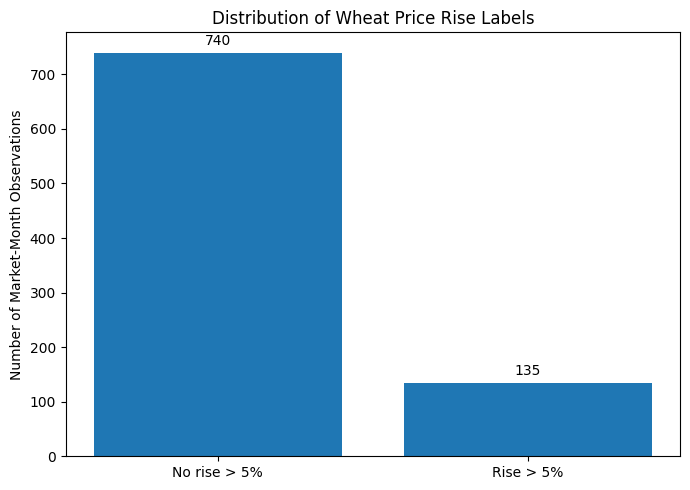

تم حفظ: /content/marketshield_corrected_outputs/figures/01_target_distribution.png


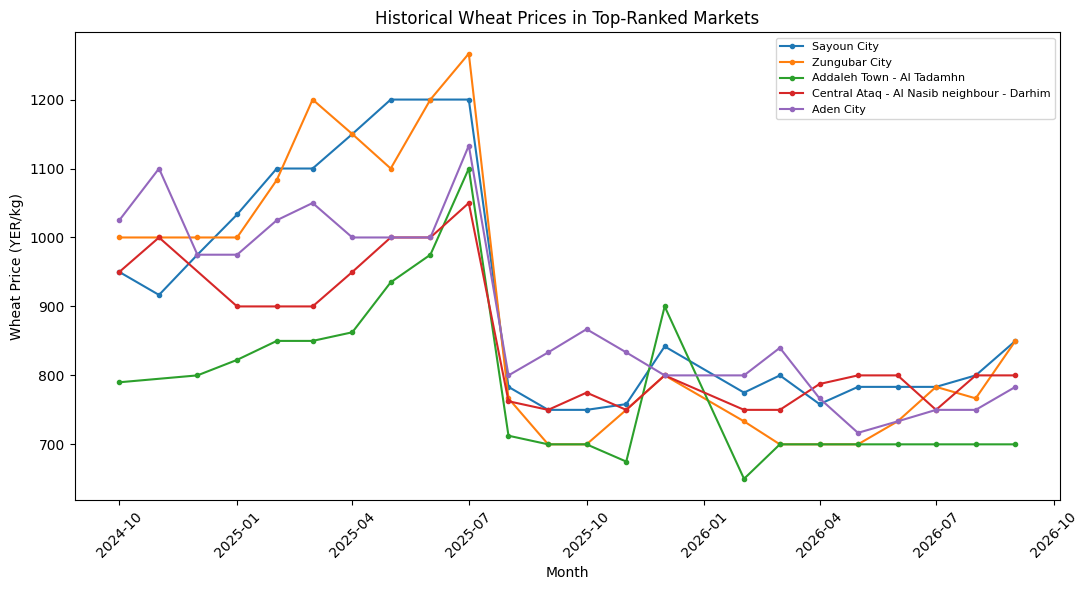

تم حفظ: /content/marketshield_corrected_outputs/figures/02_wheat_price_trends.png


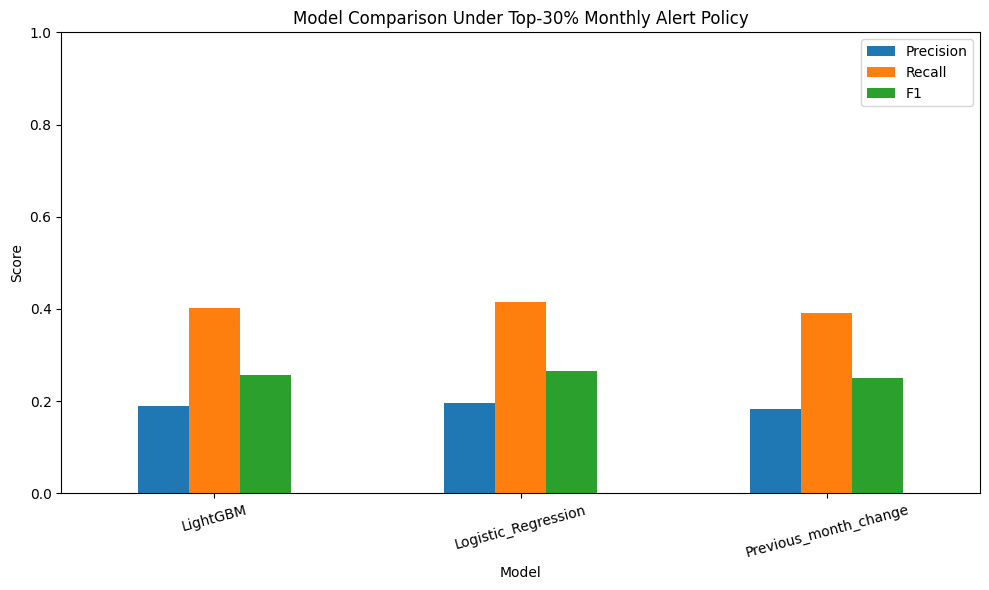

تم حفظ: /content/marketshield_corrected_outputs/figures/03_model_performance_comparison.png


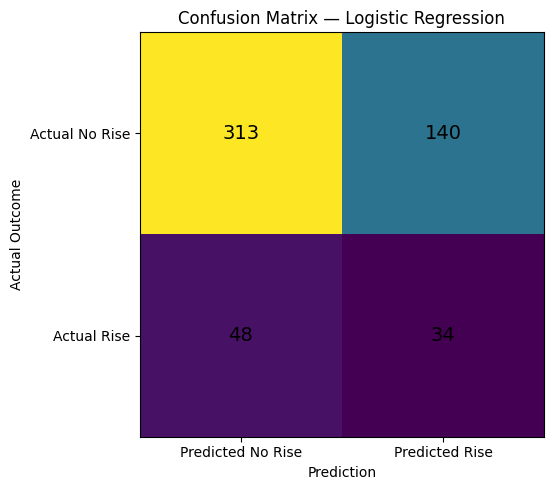

تم حفظ: /content/marketshield_corrected_outputs/figures/04_logistic_confusion_matrix.png


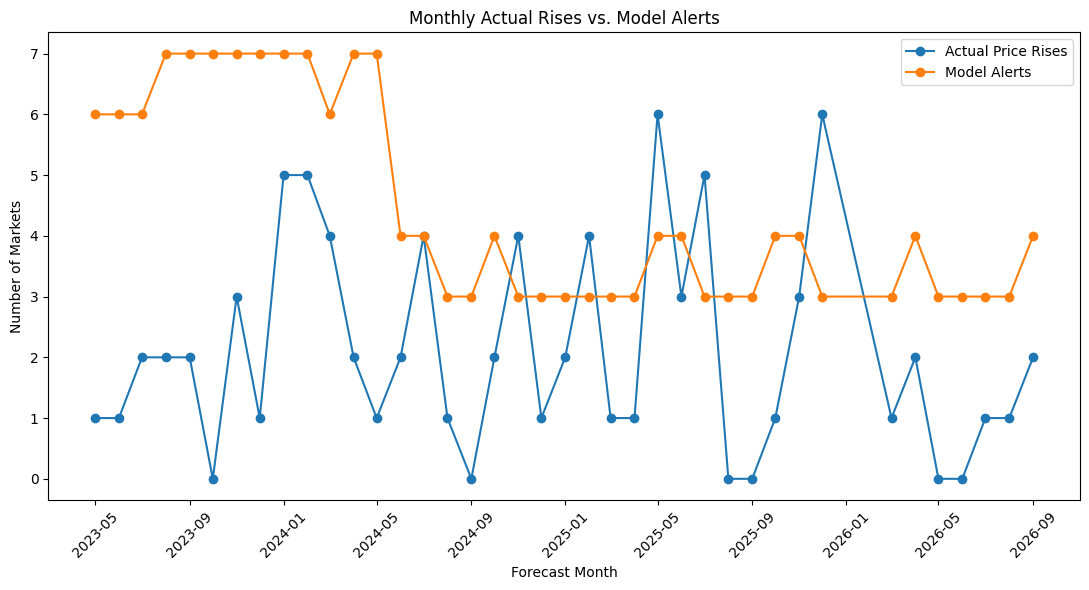

تم حفظ: /content/marketshield_corrected_outputs/figures/05_monthly_alerts_vs_actual.png


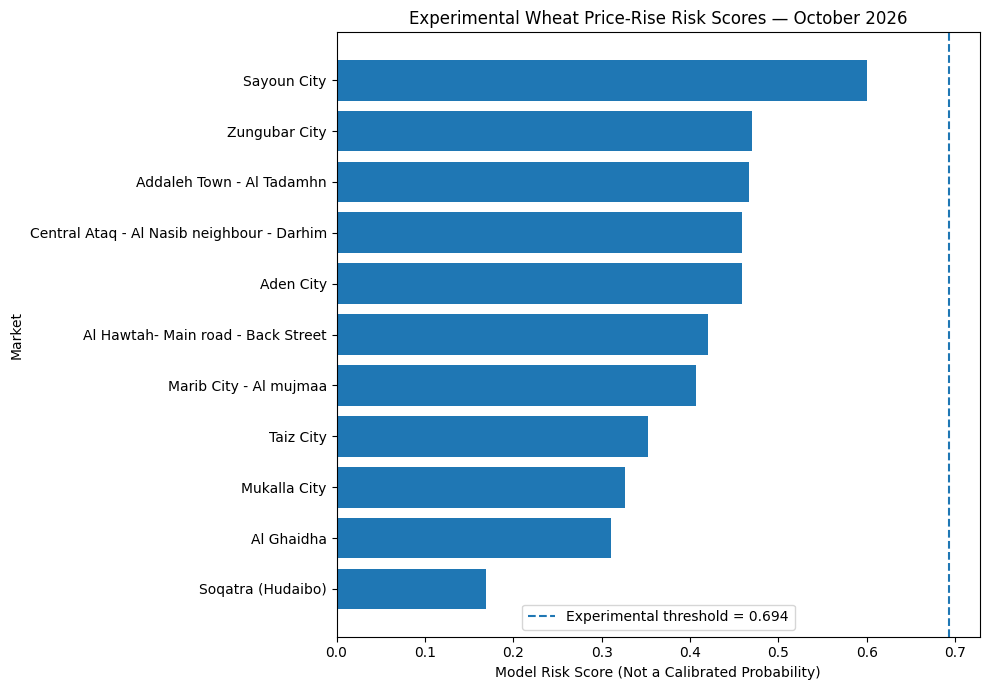

تم حفظ: /content/marketshield_corrected_outputs/figures/06_october_2026_risk_scores.png

اكتملت عملية إنشاء الرسوم.
مجلد الرسوم: /content/marketshield_corrected_outputs/figures
عدد الرسوم المحفوظة: 6
الحزمة المحدثة: /content/Yemen_MarketShield_Corrected_Results.zip


In [20]:
from pathlib import Path
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =========================================================
# 1. تجهيز الملفات
# =========================================================
BASE = Path("/content/marketshield_corrected_outputs")
FIG_DIR = BASE / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

required_files = [
    "forecast_df_v3.csv",
    "monthly_panel_v3.csv",
    "top30_policy_monthly.csv",
    "top30_policy_summary.csv",
    "october_2026_research_forecast.csv",
]

missing = [f for f in required_files if not (BASE / f).exists()]
if missing:
    raise FileNotFoundError(
        "الملفات التالية غير موجودة:\n" + "\n".join(missing)
    )

labeled = pd.read_csv(BASE / "forecast_df_v3.csv")
panel = pd.read_csv(BASE / "monthly_panel_v3.csv")
monthly = pd.read_csv(BASE / "top30_policy_monthly.csv")
summary = pd.read_csv(BASE / "top30_policy_summary.csv")
october = pd.read_csv(BASE / "october_2026_research_forecast.csv")

for frame, col in [
    (labeled, "period_month"),
    (panel, "period_month"),
    (monthly, "forecast_month"),
    (october, "forecast_month"),
]:
    if col in frame.columns:
        frame[col] = pd.to_datetime(frame[col], errors="coerce")

def save_figure(filename):
    path = FIG_DIR / filename
    plt.tight_layout()
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()
    print("تم حفظ:", path)

# =========================================================
# الرسم 1: توزيع حالات ارتفاع الأسعار
# =========================================================
target_col = "next_rise_gt5"

if target_col not in labeled.columns:
    raise KeyError(f"العمود المطلوب غير موجود: {target_col}")

counts = labeled[target_col].dropna().astype(int).value_counts()
negative = int(counts.get(0, 0))
positive = int(counts.get(1, 0))

plt.figure(figsize=(7, 5))
bars = plt.bar(
    ["No rise > 5%", "Rise > 5%"],
    [negative, positive]
)
plt.title("Distribution of Wheat Price Rise Labels")
plt.ylabel("Number of Market-Month Observations")
plt.bar_label(bars, padding=3)
save_figure("01_target_distribution.png")

# =========================================================
# الرسم 2: اتجاه الأسعار في الأسواق الأعلى ترتيبًا
# =========================================================
top_markets = (
    october.sort_values("risk_score", ascending=False)
    ["market_name"]
    .dropna()
    .drop_duplicates()
    .head(5)
    .tolist()
)

price_data = panel.loc[
    panel["market_name"].isin(top_markets)
    & panel["price"].notna()
].copy()

if not price_data.empty:
    cutoff = price_data["period_month"].max() - pd.DateOffset(months=23)
    price_data = price_data.loc[
        price_data["period_month"] >= cutoff
    ]

    plt.figure(figsize=(11, 6))
    for market in top_markets:
        part = price_data.loc[
            price_data["market_name"] == market
        ].sort_values("period_month")

        if not part.empty:
            plt.plot(
                part["period_month"],
                part["price"],
                marker="o",
                markersize=3,
                label=market
            )

    plt.title("Historical Wheat Prices in Top-Ranked Markets")
    plt.xlabel("Month")
    plt.ylabel("Wheat Price (YER/kg)")
    plt.xticks(rotation=45)
    plt.legend(fontsize=8, loc="best")
    save_figure("02_wheat_price_trends.png")
else:
    print("تجاوز الرسم 2: لا توجد أسعار متاحة للأسواق المختارة.")

# =========================================================
# الرسم 3: مقارنة الأداء المجمع للنماذج
# =========================================================
required_metrics = [
    "model", "pooled_precision", "pooled_recall", "pooled_f1"
]
missing_metrics = [
    c for c in required_metrics if c not in summary.columns
]

if missing_metrics:
    raise KeyError(
        "أعمدة المقارنة غير موجودة: " + ", ".join(missing_metrics)
    )

metric_plot = summary.set_index("model")[
    ["pooled_precision", "pooled_recall", "pooled_f1"]
].rename(columns={
    "pooled_precision": "Precision",
    "pooled_recall": "Recall",
    "pooled_f1": "F1"
})

ax = metric_plot.plot(kind="bar", figsize=(10, 6))
ax.set_title("Model Comparison Under Top-30% Monthly Alert Policy")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=15)
save_figure("03_model_performance_comparison.png")

# =========================================================
# الرسم 4: مصفوفة الالتباس للانحدار اللوجستي
# =========================================================
lr = monthly.loc[
    monthly["model"] == "Logistic_Regression"
]

if lr.empty:
    print("تجاوز الرسم 4: لم توجد نتائج Logistic_Regression.")
else:
    tp = int(lr["TP"].sum())
    fp = int(lr["FP"].sum())
    fn = int(lr["FN"].sum())
    tn = int(lr["TN"].sum())

    cm = np.array([[tn, fp], [fn, tp]])

    plt.figure(figsize=(6, 5))
    plt.imshow(cm, interpolation="nearest")
    plt.title("Confusion Matrix — Logistic Regression")
    plt.xticks([0, 1], ["Predicted No Rise", "Predicted Rise"])
    plt.yticks([0, 1], ["Actual No Rise", "Actual Rise"])
    plt.xlabel("Prediction")
    plt.ylabel("Actual Outcome")

    for i in range(2):
        for j in range(2):
            plt.text(
                j, i, f"{cm[i, j]:,}",
                ha="center", va="center", fontsize=14
            )

    save_figure("04_logistic_confusion_matrix.png")

# =========================================================
# الرسم 5: التنبيهات مقابل الارتفاعات الفعلية شهريًا
# =========================================================
lr_months = lr.sort_values("forecast_month").copy()

if not lr_months.empty:
    plt.figure(figsize=(11, 6))
    plt.plot(
        lr_months["forecast_month"],
        lr_months["actual_rises"],
        marker="o",
        label="Actual Price Rises"
    )
    plt.plot(
        lr_months["forecast_month"],
        lr_months["alerts"],
        marker="o",
        label="Model Alerts"
    )

    plt.title("Monthly Actual Rises vs. Model Alerts")
    plt.xlabel("Forecast Month")
    plt.ylabel("Number of Markets")
    plt.xticks(rotation=45)
    plt.legend()
    save_figure("05_monthly_alerts_vs_actual.png")

# =========================================================
# الرسم 6: ترتيب مخاطر أكتوبر 2026
# =========================================================
oct_plot = october.sort_values("risk_score", ascending=True).copy()

if not oct_plot.empty:
    plt.figure(figsize=(10, 7))
    plt.barh(oct_plot["market_name"], oct_plot["risk_score"])

    threshold = float(oct_plot["threshold"].iloc[0])
    plt.axvline(
        threshold,
        linestyle="--",
        label=f"Experimental threshold = {threshold:.3f}"
    )

    plt.title("Experimental Wheat Price-Rise Risk Scores — October 2026")
    plt.xlabel("Model Risk Score (Not a Calibrated Probability)")
    plt.ylabel("Market")
    plt.legend()
    save_figure("06_october_2026_risk_scores.png")

# =========================================================
# 7. تحديث ملف ZIP ليشمل الرسوم
# =========================================================
zip_path = Path("/content/Yemen_MarketShield_Corrected_Results.zip")

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for path in sorted(BASE.rglob("*")):
        if path.is_file():
            zf.write(
                path,
                arcname=f"marketshield_corrected_outputs/{path.relative_to(BASE)}"
            )

print("\nاكتملت عملية إنشاء الرسوم.")
print("مجلد الرسوم:", FIG_DIR)
print("عدد الرسوم المحفوظة:", len(list(FIG_DIR.glob("*.png"))))
print("الحزمة المحدثة:", zip_path)

In [21]:
from google.colab import files

files.download(
    "/content/Yemen_MarketShield_Corrected_Results.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## الخلاصة

- `forecast_df_v3.csv` هو جدول التدريب الصحيح: سعر الشهر الحالي، الميزات المحسوبة من الماضي، والسعر الفعلي للشهر التالي مع الهدف `next_rise_gt5`.
- `october_2026_research_forecast.csv` هو الناتج المتوقع لشهر أكتوبر للأسواق التي لديها سعر سبتمبر.
- الأرشيفات الاقتصادية القديمة لا تدخل في نموذج أكتوبر. إذا أردنا استخدامها في نسخة لاحقة، يجب أولًا الحصول على تحديثات مرصودة حديثة والتحقق يدويًا من مطابقة الأسواق.
- لا تعتبر عتبات الإنذار أو درجات المخاطر توصية اقتصادية، ولا تنشرها كنظام تنبيه فعلي دون تحقق خارجي مستقبلي.